
# P1 — Supervised Classification

This notebook evaluates classical machine-learning and deep-learning classifiers for two photovoltaic classification tasks using data from **Davis and Amherst**.

## 1. Classification Tasks

### Task A — Sky-Condition Classification

Sky conditions are categorized using the Clear-Sky Index (CSI):

$$
\mathrm{CSI} = \frac{\mathrm{GHI}}{\text{Clearsky GHI}}
$$

- **Clear:** CSI ≥ 0.85
- **Partly Cloudy:** 0.40 ≤ CSI < 0.85
- **Overcast:** CSI < 0.40

GHI, Clearsky GHI, and CSI are excluded from the predictor features to prevent direct label leakage. Output Power is initially included, with an additional feature-ablation experiment to assess its contribution.

### Task B — Power-Generation Regime Classification

Output Power is categorized into **Low, Medium, and High** generation regimes using city-specific tercile thresholds calculated from the training data.

Output Power is excluded from the predictor features to prevent target leakage.

## 2. Experimental Setup

- **Datasets:** Davis (2014–2016) and Amherst (2018–2020).
- **Data splitting:** Chronological 80% training and 20% testing.
- **Reproducibility:** Three fixed random seeds (42, 123, 2026).
- **Methods:** Multiple classical classifiers and at least one deep-learning classifier.
- **Preprocessing:** Feature transformations are fitted using training data only.

## 3. Evaluation Metrics

### Balanced Accuracy (Primary Metric)

Recall measures the proportion of actual samples from a class that are correctly identified:

$$
\mathrm{Recall}_c = \frac{TP_c}{TP_c + FN_c}
$$

Balanced accuracy is the average recall across all classes:

$$
\boxed{
\mathrm{Balanced\ Accuracy}
=
\frac{1}{C}
\sum_{c=1}^{C}
\frac{TP_c}{TP_c+FN_c}
}
$$

For the three-class classification tasks, C = 3.

### Macro-F1 Score (Additional Metric)

The F1 score combines precision and recall:

$$
F1_c =
\frac{2TP_c}{2TP_c+FP_c+FN_c}
$$

$$
\mathrm{Macro\text{-}F1}
=
\frac{1}{C}\sum_{c=1}^{C}F1_c
$$

### Confusion Matrix

Confusion matrices visualize correct predictions and misclassifications across the three classes. Per-class precision, recall, and F1 scores provide additional diagnostic information.

## 4. Results and Visualization

- Compare all evaluated models using balanced accuracy and macro-F1.
- Generate confusion matrices for all models.
- Identify the best-performing model for each task and city.
- Discuss the best models and the most challenging classification categories.
- Export final leaderboards and figures as vector PDFs for the project report.

Experiment metrics and predictions are saved separately, allowing figures to be regenerated without retraining.


In [1]:

# ============================================================
# P1 — Cell 2: Environment Setup and Dataset Loading
# ============================================================

import os
import platform
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display


# ------------------------------------------------------------
# 1. Locate the project (Colab or local Jupyter)
# ------------------------------------------------------------

PROJECT_NAME = "Code_base_v2"

# Optional: specify a custom project location.
# Leave as None for automatic detection.
PROJECT_ROOT_OVERRIDE = None

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive")


def locate_project():

    configured = (
        PROJECT_ROOT_OVERRIDE
        or os.environ.get("ECE579_PROJECT_ROOT")
    )

    if configured:
        root = Path(configured).expanduser().resolve()
        if not root.is_dir():
            raise FileNotFoundError(root)
        return root

    current = Path.cwd().resolve()

    # Works when Jupyter starts inside or beside the project.
    for folder in [current, *current.parents]:
        if (folder / "Data" / "Processed").is_dir():
            return folder

        candidate = folder / PROJECT_NAME
        if (candidate / "Data" / "Processed").is_dir():
            return candidate

    # Default location for this project's Google Drive setup.
    if IN_COLAB:
        candidate = (
            Path("/content/drive/MyDrive")
            / "Colab Notebooks"
            / "ML_ECE_571_Project"
            / PROJECT_NAME
        )

        if candidate.is_dir():
            return candidate

    raise FileNotFoundError(
        "Project not found. Set PROJECT_ROOT_OVERRIDE "
        "to the Code_base_v2 directory."
    )


PROJECT_ROOT = locate_project()
PROCESSED_DIR = PROJECT_ROOT / "Data" / "Processed"
SPLITS_DIR = PROCESSED_DIR / "Splits"
RESULTS_DIR = PROJECT_ROOT / "Results" / "P1"
FIGURES_DIR = PROJECT_ROOT / "Figures" / "P1"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

SEEDS = (42, 123, 2026)

DATASETS = {
    "Davis": "Davis_2014_2016",
    "Amherst": "Amherst_2018_2020"
}


# ------------------------------------------------------------
# 2. Load data and reuse saved chronological splits
# ------------------------------------------------------------

CITY_DATA = {}

for city, dataset_name in DATASETS.items():

    data_path = PROCESSED_DIR / f"{dataset_name}.csv"

    split_path = (
        SPLITS_DIR
        / f"{dataset_name}_chronological_80_20.csv"
    )

    df = pd.read_csv(data_path, parse_dates=["Timestamp"])
    splits = pd.read_csv(split_path, parse_dates=["Timestamp"])

    # Verify that saved split indices match the loaded data.
    assert len(df) == len(splits)
    np.testing.assert_array_equal(
        df["row_index"].to_numpy(),
        splits["row_index"].to_numpy()
    )
    np.testing.assert_array_equal(
        df["Timestamp"].to_numpy(),
        splits["Timestamp"].to_numpy()
    )

    train_mask = splits["split"].eq("train").to_numpy()
    test_mask = splits["split"].eq("test").to_numpy()

    assert (train_mask | test_mask).all()
    assert not (train_mask & test_mask).any()

    assert (
        df.loc[train_mask, "Timestamp"].max()
        < df.loc[test_mask, "Timestamp"].min()
    )

    CITY_DATA[city] = {
        "data": df,
        "train_mask": train_mask,
        "test_mask": test_mask
    }


# ------------------------------------------------------------
# 3. Display loaded dataset information
# ------------------------------------------------------------

summary = []

for city, item in CITY_DATA.items():

    df = item["data"]
    train_mask = item["train_mask"]
    test_mask = item["test_mask"]

    summary.append({
        "City": city,
        "Total": len(df),
        "Train": int(train_mask.sum()),
        "Test": int(test_mask.sum()),
        "Missing Power": int(df["Output Power"].isna().sum()),
        "Start": df["Timestamp"].min().date(),
        "End": df["Timestamp"].max().date()
    })

print("P1 — CLASSIFICATION DATASET SETUP")
print("=" * 65)
print(f"Platform     : {platform.system()}")
print(f"Project      : {PROJECT_ROOT}")
print(f"Random seeds : {SEEDS}")
print("\nLoaded datasets:")
display(pd.DataFrame(summary))

print("Chronological splits verified.")
print("No preprocessing fitted and no test data used for training.")


Mounted at /content/drive
P1 — CLASSIFICATION DATASET SETUP
Platform     : Linux
Project      : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2
Random seeds : (42, 123, 2026)

Loaded datasets:


,City,Total,Train,Test,Missing Power,Start,End
0,Davis,12056,9644,2412,0,2014-01-01,2016-12-31
1,Amherst,12056,9644,2412,4,2018-01-01,2020-12-31


Chronological splits verified.
No preprocessing fitted and no test data used for training.


In [2]:

# ============================================================
# P1 — Cell 3: Classification Targets and Distributions
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display

CLASS_NAMES = {
    "Sky": ["Overcast", "Partly Cloudy", "Clear"],
    "Generation": ["Low", "Medium", "High"]
}

P1_LABELS = {}
distribution_records = []


# ------------------------------------------------------------
# 1. Construct classification targets for each city
# ------------------------------------------------------------

for city, item in CITY_DATA.items():

    df = item["data"]
    train_mask = item["train_mask"]
    test_mask = item["test_mask"]

    power = df["Output Power"].to_numpy(dtype=float)
    valid_power = np.isfinite(power)

    # --------------------------------------------------------
    # Task A — Sky-condition classification
    # --------------------------------------------------------

    ghi = df["GHI"].to_numpy(dtype=float)
    clear_ghi = df["Clearsky GHI"].to_numpy(dtype=float)

    csi = np.full(len(df), np.nan, dtype=float)

    np.divide(
        ghi,
        clear_ghi,
        out=csi,
        where=clear_ghi > 0
    )

    valid_csi = np.isfinite(csi) & (clear_ghi > 0)

    # Output Power is included in the main sky classifier.
    # The later feature ablation uses identical observations.
    sky_eligible = valid_csi & valid_power

    sky_labels = np.full(len(df), -1, dtype=int)

    sky_labels[sky_eligible] = np.select(
        [
            csi[sky_eligible] < 0.40,
            csi[sky_eligible] < 0.85
        ],
        [0, 1],
        default=2
    )

    # --------------------------------------------------------
    # Task B — Power-generation regime classification
    # --------------------------------------------------------

    # Tercile thresholds are estimated from training data only.
    train_power = power[train_mask & valid_power]

    q_low, q_high = np.quantile(
        train_power,
        [1 / 3, 2 / 3]
    )

    if not q_low < q_high:
        raise ValueError(
            f"{city}: Power terciles are not distinct. "
            "The generation-label strategy needs review."
        )

    generation_eligible = valid_power

    generation_labels = np.full(
        len(df), -1, dtype=int
    )

    generation_labels[generation_eligible] = np.searchsorted(
        [q_low, q_high],
        power[generation_eligible],
        side="left"
    )

    # --------------------------------------------------------
    # Store labels and eligibility masks for subsequent cells
    # --------------------------------------------------------

    P1_LABELS[city] = {
        "Sky": {
            "y": sky_labels,
            "eligible": sky_eligible
        },
        "Generation": {
            "y": generation_labels,
            "eligible": generation_eligible,
            "terciles": (q_low, q_high)
        }
    }

    print(f"\n{city.upper()}")
    print("-" * 65)
    print(
        f"Invalid/undefined CSI observations: "
        f"{(~valid_csi).sum()}"
    )
    print(
        f"Missing Output Power observations: "
        f"{(~valid_power).sum()}"
    )
    print(
        f"Training power terciles: "
        f"{q_low:.4f}, {q_high:.4f}"
    )

    # --------------------------------------------------------
    # Calculate class distributions
    # --------------------------------------------------------

    for task in ("Sky", "Generation"):

        task_data = P1_LABELS[city][task]

        y = task_data["y"]
        eligible = task_data["eligible"]

        train_valid = train_mask & eligible
        test_valid = test_mask & eligible

        n_train = int(train_valid.sum())
        n_test = int(test_valid.sum())

        train_counts = np.bincount(
            y[train_valid], minlength=3
        )

        test_counts = np.bincount(
            y[test_valid], minlength=3
        )

        if n_train == 0 or n_test == 0:
            raise ValueError(
                f"{city}, {task}: No eligible train/test samples."
            )

        if (train_counts == 0).any():
            raise ValueError(
                f"{city}, {task}: A training class is absent."
            )

        for class_id, class_name in enumerate(
            CLASS_NAMES[task]
        ):

            distribution_records.append({
                "City": city,
                "Task": task,
                "Class": class_name,
                "Train Count": int(train_counts[class_id]),
                "Train %": round(
                    100 * train_counts[class_id] / n_train, 2
                ),
                "Test Count": int(test_counts[class_id]),
                "Test %": round(
                    100 * test_counts[class_id] / n_test, 2
                )
            })


# ------------------------------------------------------------
# 2. Display class distributions
# ------------------------------------------------------------

class_distribution = pd.DataFrame(distribution_records)

print("\nCLASS DISTRIBUTIONS")
print("=" * 85)

display(class_distribution)


# ------------------------------------------------------------
# 3. Summarize eligible samples
# ------------------------------------------------------------

sample_records = []

for city, item in CITY_DATA.items():

    for task in ("Sky", "Generation"):

        eligible = P1_LABELS[city][task]["eligible"]

        sample_records.append({
            "City": city,
            "Task": task,
            "Training Samples": int(
                (item["train_mask"] & eligible).sum()
            ),
            "Testing Samples": int(
                (item["test_mask"] & eligible).sum()
            ),
            "Excluded Samples": int((~eligible).sum())
        })

print("\nELIGIBLE SAMPLES")
display(pd.DataFrame(sample_records))

print("\nBoth classification targets generated successfully.")
print("No model preprocessing has been fitted.")
print("No files have been modified or overwritten.")



DAVIS
-----------------------------------------------------------------
Invalid/undefined CSI observations: 0
Missing Output Power observations: 0
Training power terciles: 135.1338, 208.9672

AMHERST
-----------------------------------------------------------------
Invalid/undefined CSI observations: 0
Missing Output Power observations: 4
Training power terciles: 29.7367, 89.1000

CLASS DISTRIBUTIONS


,City,Task,Class,Train Count,Train %,Test Count,Test %
0,Davis,Sky,Overcast,884,9.17,177,7.34
1,Davis,Sky,Partly Cloudy,1877,19.46,280,11.61
2,Davis,Sky,Clear,6883,71.37,1955,81.05
3,Davis,Generation,Low,3215,33.34,745,30.89
4,Davis,Generation,Medium,3214,33.33,730,30.27
5,Davis,Generation,High,3215,33.34,937,38.85
6,Amherst,Sky,Overcast,2553,26.47,604,25.08
7,Amherst,Sky,Partly Cloudy,3164,32.81,650,26.99
8,Amherst,Sky,Clear,3927,40.72,1154,47.92
9,Amherst,Generation,Low,3215,33.34,658,27.33



ELIGIBLE SAMPLES


,City,Task,Training Samples,Testing Samples,Excluded Samples
0,Davis,Sky,9644,2412,0
1,Davis,Generation,9644,2412,0
2,Amherst,Sky,9644,2408,4
3,Amherst,Generation,9644,2408,4



Both classification targets generated successfully.
No model preprocessing has been fitted.
No files have been modified or overwritten.


In [3]:

# ============================================================
# P1 — Cell 4: Feature Preparation and Validation Setup
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display


# ------------------------------------------------------------
# 1. Define permitted predictor features
# ------------------------------------------------------------

WEATHER_FEATURES = [
    "DHI", "DNI",
    "Clearsky DHI", "Clearsky DNI",
    "Dew Point", "Solar Zenith Angle",
    "Surface Albedo", "Wind Speed",
    "Precipitable Water", "Wind Direction",
    "Relative Humidity", "Temperature", "Pressure"
]

TIME_FEATURES = [
    "Hour_sin", "Hour_cos",
    "DayOfYear_sin", "DayOfYear_cos"
]

CATEGORICAL_FEATURES = ["Cloud Type"]

TASK_NUMERIC_FEATURES = {
    "Sky": WEATHER_FEATURES + TIME_FEATURES + ["Output Power"],
    "Generation": WEATHER_FEATURES + TIME_FEATURES
                  + ["GHI", "Clearsky GHI"]
}


# ------------------------------------------------------------
# 2. Construct features without learning from the data
# ------------------------------------------------------------

def build_p1_features(df, task, include_power=True):
    """
    Create predictor features using fixed, deterministic
    transformations. No statistics are learned or fitted.
    """

    if task not in ("Sky", "Generation"):
        raise ValueError(f"Unknown task: {task}")

    numeric_columns = TASK_NUMERIC_FEATURES[task].copy()

    if task == "Sky" and not include_power:
        numeric_columns.remove("Output Power")

    features = df[
        [col for col in numeric_columns
         if col not in TIME_FEATURES]
    ].copy()

    # Fractional hour preserves the original 30-minute steps.
    hour = (
        df["Timestamp"].dt.hour
        + df["Timestamp"].dt.minute / 60
    )

    day_of_year = df["Timestamp"].dt.dayofyear

    features["Hour_sin"] = np.sin(
        2 * np.pi * hour / 24
    )
    features["Hour_cos"] = np.cos(
        2 * np.pi * hour / 24
    )

    features["DayOfYear_sin"] = np.sin(
        2 * np.pi * day_of_year / 365.25
    )
    features["DayOfYear_cos"] = np.cos(
        2 * np.pi * day_of_year / 365.25
    )

    # Cloud Type is categorical, not a continuous measurement.
    features["Cloud Type"] = (
        df["Cloud Type"].astype("string").astype(str)
    )

    # Preserve an identical, documented column order.
    return features[numeric_columns + CATEGORICAL_FEATURES]


# ------------------------------------------------------------
# 3. Define chronological training/validation partitions
# ------------------------------------------------------------

P1_FEATURES = {}
P1_PARTITIONS = {}
feature_records = []

for city, item in CITY_DATA.items():

    df = item["data"]
    train_indices = np.flatnonzero(item["train_mask"])

    # Validation uses the final 20% of the training partition.
    validation_start = int(0.80 * len(train_indices))

    fit_indices = train_indices[:validation_start]
    val_indices = train_indices[validation_start:]

    assert len(fit_indices) > 0
    assert len(val_indices) > 0
    assert fit_indices.max() < val_indices.min()
    assert val_indices.max() < np.flatnonzero(
        item["test_mask"]
    ).min()

    P1_PARTITIONS[city] = {
        "fit_indices": fit_indices,
        "val_indices": val_indices,
        "train_mask": item["train_mask"],
        "test_mask": item["test_mask"]
    }

    P1_FEATURES[city] = {
        "Sky": build_p1_features(df, "Sky"),
        "Generation": build_p1_features(df, "Generation"),
        "Sky_NoPower": build_p1_features(
            df, "Sky", include_power=False
        )
    }

    for task in ("Sky", "Generation"):

        features = P1_FEATURES[city][task]
        eligible = P1_LABELS[city][task]["eligible"]

        # Every model input must be valid for eligible rows.
        numeric_cols = [
            col for col in features.columns
            if col != "Cloud Type"
        ]

        assert np.isfinite(
            features.loc[eligible, numeric_cols]
            .to_numpy(dtype=float)
        ).all()

        assert features.loc[
            eligible, "Cloud Type"
        ].notna().all()

        # Validation must contain all three classes.
        val_eligible = np.zeros(len(df), dtype=bool)
        val_eligible[val_indices] = True
        val_eligible &= eligible

        val_classes = np.unique(
            P1_LABELS[city][task]["y"][val_eligible]
        )

        assert len(val_classes) == 3, (
            f"{city}, {task}: Missing validation class."
        )

        feature_records.append({
            "City": city,
            "Task": task,
            "Features": features.shape[1],
            "Fit Samples": int(
                eligible[fit_indices].sum()
            ),
            "Validation Samples": int(
                eligible[val_indices].sum()
            ),
            "Test Samples": int(
                (eligible & item["test_mask"]).sum()
            )
        })


# ------------------------------------------------------------
# 4. Display experiment preparation summary
# ------------------------------------------------------------

print("P1 — FEATURE AND VALIDATION SETUP")
print("=" * 75)

display(pd.DataFrame(feature_records))

print("\nSky-condition predictors:")
print(P1_FEATURES["Davis"]["Sky"].columns.tolist())

print("\nGeneration-regime predictors:")
print(P1_FEATURES["Davis"]["Generation"].columns.tolist())

print("\nValidation strategy:")
print("  Model fitting   : First 64% of all observations")
print("  Model selection : Next 16% of all observations")
print("  Final testing   : Last 20% of all observations")

print("\nFeature preparation completed.")
print("Encoding and scaling will be fitted only on training data.")


P1 — FEATURE AND VALIDATION SETUP


,City,Task,Features,Fit Samples,Validation Samples,Test Samples
0,Davis,Sky,19,7715,1929,2412
1,Davis,Generation,20,7715,1929,2412
2,Amherst,Sky,19,7715,1929,2408
3,Amherst,Generation,20,7715,1929,2408



Sky-condition predictors:
['DHI', 'DNI', 'Clearsky DHI', 'Clearsky DNI', 'Dew Point', 'Solar Zenith Angle', 'Surface Albedo', 'Wind Speed', 'Precipitable Water', 'Wind Direction', 'Relative Humidity', 'Temperature', 'Pressure', 'Hour_sin', 'Hour_cos', 'DayOfYear_sin', 'DayOfYear_cos', 'Output Power', 'Cloud Type']

Generation-regime predictors:
['DHI', 'DNI', 'Clearsky DHI', 'Clearsky DNI', 'Dew Point', 'Solar Zenith Angle', 'Surface Albedo', 'Wind Speed', 'Precipitable Water', 'Wind Direction', 'Relative Humidity', 'Temperature', 'Pressure', 'Hour_sin', 'Hour_cos', 'DayOfYear_sin', 'DayOfYear_cos', 'GHI', 'Clearsky GHI', 'Cloud Type']

Validation strategy:
  Model fitting   : First 64% of all observations
  Model selection : Next 16% of all observations
  Final testing   : Last 20% of all observations

Feature preparation completed.
Encoding and scaling will be fitted only on training data.


In [7]:

# ============================================================
# P1 — Cell 5: Model Definitions and Shared Utilities
# ============================================================

import random
import numpy as np
import pandas as pd
import sklearn
import xgboost
import torch
import torch.nn as nn

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from sklearn.utils.class_weight import compute_sample_weight


# ------------------------------------------------------------
# 1. Reproducibility and hardware configuration
# ------------------------------------------------------------

def set_experiment_seed(seed):
    """Set random seeds for reproducible experiments."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif (
    hasattr(torch.backends, "mps")
    and torch.backends.mps.is_available()
):
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")


# ------------------------------------------------------------
# 2. Define all classification models
# ------------------------------------------------------------

CLASSICAL_MODELS = (
    "Logistic Regression",
    "SVM (RBF)",
    "Random Forest",
    "XGBoost"
)

DEEP_MODELS = ("MLP (PyTorch)",)

ALL_MODELS = CLASSICAL_MODELS + DEEP_MODELS


def create_classifier(model_name, seed):
    """Initialize a classical classifier."""

    if model_name == "Logistic Regression":
        return LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=seed
        )

    elif model_name == "SVM (RBF)":
        return SVC(
            kernel="rbf",
            C=3.0,
            gamma="scale",
            class_weight="balanced"
        )

    elif model_name == "Random Forest":
        return RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=2,
            class_weight="balanced_subsample",
            random_state=seed,
            n_jobs=-1
        )

    elif model_name == "XGBoost":
        return XGBClassifier(
            objective="multi:softprob",
            num_class=3,
            n_estimators=250,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.9,
            colsample_bytree=0.9,
            reg_lambda=1.0,
            tree_method="hist",
            eval_metric="mlogloss",
            random_state=seed,
            n_jobs=-1
        )

    else:
        raise ValueError(
            f"Unknown classical model: {model_name}"
        )


# ------------------------------------------------------------
# 3. Define the PyTorch MLP
# ------------------------------------------------------------

class MLPClassifier(nn.Module):
    """
    Multilayer perceptron for three-class classification.

    Architecture:
        Input -> 128 -> 64 -> 3

    Hidden layers use ReLU activation and dropout.
    The final layer produces logits for cross-entropy loss.
    """

    def __init__(self, input_dim, num_classes=3):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.15),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.15),

            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.network(x)


MLP_CONFIG = {
    "learning_rate": 0.001,
    "batch_size": 256,
    "max_epochs": 80,
    "patience": 10,
    "weight_decay": 0.0001
}


# ------------------------------------------------------------
# 4. Define training-only preprocessing
# ------------------------------------------------------------

def create_preprocessor(X):
    """
    Standardize numerical predictors and one-hot encode
    Cloud Type.

    The transformer is fitted exclusively on the
    training partition supplied to its fit method.
    """

    categorical_columns = ["Cloud Type"]

    numerical_columns = [
        col for col in X.columns
        if col not in categorical_columns
    ]

    # Support older and newer scikit-learn versions.
    try:
        encoder = OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    except TypeError:
        encoder = OneHotEncoder(
            handle_unknown="ignore",
            sparse=False
        )

    return ColumnTransformer(
        transformers=[
            (
                "numeric",
                StandardScaler(),
                numerical_columns
            ),
            (
                "categorical",
                encoder,
                categorical_columns
            )
        ],
        remainder="drop",
        sparse_threshold=0
    )


def create_pipeline(model_name, X, seed):
    """
    Construct a classical classification pipeline.

    Preprocessing is fitted only when pipeline.fit()
    is called on the selected training data.
    """

    if model_name not in CLASSICAL_MODELS:
        raise ValueError(
            "This pipeline supports classical models only."
        )

    return Pipeline([
        (
            "preprocessor",
            create_preprocessor(X)
        ),
        (
            "classifier",
            create_classifier(model_name, seed)
        )
    ])


def fit_classical_pipeline(pipeline, model_name, X, y):
    """
    Fit a classical classifier.

    Class imbalance is addressed through model-specific
    class weights or per-sample weights.
    """

    if model_name == "XGBoost":

        sample_weights = compute_sample_weight(
            class_weight="balanced",
            y=y
        )

        pipeline.fit(
            X,
            y,
            classifier__sample_weight=sample_weights
        )

    else:
        pipeline.fit(X, y)

    return pipeline


# ------------------------------------------------------------
# 5. Retrieve classification data partitions
# ------------------------------------------------------------

def get_p1_partition(
    city,
    task,
    partition,
    without_power=False
):
    """
    Return eligible features, labels, and row indices.

    Supported partitions:
        fit, validation, train, test

    without_power=True is reserved for the
    sky-condition feature-ablation experiment.
    """

    if city not in CITY_DATA:
        raise ValueError(f"Unknown city: {city}")

    if task not in ("Sky", "Generation"):
        raise ValueError(f"Unknown task: {task}")

    if without_power and task != "Sky":
        raise ValueError(
            "Power-feature ablation applies only to Sky."
        )

    partitions = P1_PARTITIONS[city]

    if partition == "fit":
        indices = partitions["fit_indices"]

    elif partition == "validation":
        indices = partitions["val_indices"]

    elif partition == "train":
        indices = np.flatnonzero(
            partitions["train_mask"]
        )

    elif partition == "test":
        indices = np.flatnonzero(
            partitions["test_mask"]
        )

    else:
        raise ValueError(
            f"Unknown partition: {partition}"
        )

    # Remove observations with invalid target labels.
    label_info = P1_LABELS[city][task]

    indices = indices[
        label_info["eligible"][indices]
    ]

    feature_key = (
        "Sky_NoPower"
        if task == "Sky" and without_power
        else task
    )

    X = (
        P1_FEATURES[city][feature_key]
        .iloc[indices]
        .copy()
    )

    y = label_info["y"][indices].copy()

    assert len(X) == len(y) == len(indices)
    assert np.all((y >= 0) & (y <= 2))

    return X, y, indices


# ------------------------------------------------------------
# 6. Shared classification evaluation
# ------------------------------------------------------------

def evaluate_classifier(y_true, y_pred, task):
    """
    Evaluate three-class predictions using:
        - Balanced accuracy
        - Macro-F1
        - Confusion matrix
        - Per-class precision, recall, and F1
    """

    if task not in CLASS_NAMES:
        raise ValueError(f"Unknown task: {task}")

    return {
        "Balanced Accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "Macro-F1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Confusion Matrix": confusion_matrix(
            y_true,
            y_pred,
            labels=[0, 1, 2]
        ),

        "Per-Class Report": classification_report(
            y_true,
            y_pred,
            labels=[0, 1, 2],
            target_names=CLASS_NAMES[task],
            output_dict=True,
            zero_division=0
        )
    }


# ------------------------------------------------------------
# 7. Validate feature restrictions and data partitions
# ------------------------------------------------------------

print("P1 — FEATURE AND DATA VALIDATION")
print("=" * 70)

for city in CITY_DATA:

    sky_columns = set(
        P1_FEATURES[city]["Sky"].columns
    )

    generation_columns = set(
        P1_FEATURES[city]["Generation"].columns
    )

    sky_no_power_columns = set(
        P1_FEATURES[city]["Sky_NoPower"].columns
    )

    # Prevent direct leakage in sky classification.
    assert not (
        {"GHI", "Clearsky GHI", "CSI"} & sky_columns
    )

    # Output Power is permitted for the main sky task.
    assert "Output Power" in sky_columns

    # Output Power must not predict its own regime label.
    assert "Output Power" not in generation_columns

    # Ensure the sky feature-ablation setup is valid.
    assert "Output Power" not in sky_no_power_columns

    for task in ("Sky", "Generation"):

        X_fit, y_fit, fit_rows = get_p1_partition(
            city, task, "fit"
        )

        X_val, y_val, val_rows = get_p1_partition(
            city, task, "validation"
        )

        X_test, y_test, test_rows = get_p1_partition(
            city, task, "test"
        )

        assert fit_rows.max() < val_rows.min()
        assert val_rows.max() < test_rows.min()

        assert X_fit.columns.equals(X_val.columns)
        assert X_fit.columns.equals(X_test.columns)

        assert len(np.unique(y_fit)) == 3
        assert len(np.unique(y_val)) == 3

        print(
            f"[PASS] {city:8s} | {task:10s} | "
            f"Fit: {len(X_fit):5d} | "
            f"Validation: {len(X_val):4d} | "
            f"Test: {len(X_test):4d}"
        )


# ------------------------------------------------------------
# 8. Verify PyTorch architecture and display configuration
# ------------------------------------------------------------

sample_model = MLPClassifier(
    input_dim=10,
    num_classes=3
)

sample_input = torch.zeros(2, 10)

assert sample_model(sample_input).shape == (2, 3)

parameter_count = sum(
    p.numel()
    for p in sample_model.parameters()
)

print("\nP1 — CLASSIFIER CONFIGURATION")
print("=" * 70)

print(f"scikit-learn version : {sklearn.__version__}")
print(f"XGBoost version      : {xgboost.__version__}")
print(f"PyTorch version      : {torch.__version__}")
print(f"Computing device     : {DEVICE}")

print("\nModels:")
for index, model_name in enumerate(ALL_MODELS, 1):
    print(f"  {index}. {model_name}")

print("\nMLP architecture     : Input -> 128 -> 64 -> 3")
print(f"MLP configuration    : {MLP_CONFIG}")

print(f"\nRandom seeds         : {SEEDS}")
print("Primary metric       : Balanced Accuracy")
print("Additional metric    : Macro-F1")
print("Diagnostic outputs   : Confusion Matrices, Per-Class Reports")

total_runs = (
    len(ALL_MODELS)
    * len(CITY_DATA)
    * 2
    * len(SEEDS)
)

print(f"\nMain experiment runs : {total_runs}")
print("Model definitions and validation completed.")
print("No models have been trained.")


P1 — FEATURE AND DATA VALIDATION
[PASS] Davis    | Sky        | Fit:  7715 | Validation: 1929 | Test: 2412
[PASS] Davis    | Generation | Fit:  7715 | Validation: 1929 | Test: 2412
[PASS] Amherst  | Sky        | Fit:  7715 | Validation: 1929 | Test: 2408
[PASS] Amherst  | Generation | Fit:  7715 | Validation: 1929 | Test: 2408

P1 — CLASSIFIER CONFIGURATION
scikit-learn version : 1.6.1
XGBoost version      : 3.4.1
PyTorch version      : 2.11.0+cu130
Computing device     : cuda

Models:
  1. Logistic Regression
  2. SVM (RBF)
  3. Random Forest
  4. XGBoost
  5. MLP (PyTorch)

MLP architecture     : Input -> 128 -> 64 -> 3
MLP configuration    : {'learning_rate': 0.001, 'batch_size': 256, 'max_epochs': 80, 'patience': 10, 'weight_decay': 0.0001}

Random seeds         : (42, 123, 2026)
Primary metric       : Balanced Accuracy
Additional metric    : Macro-F1
Diagnostic outputs   : Confusion Matrices, Per-Class Reports

Main experiment runs : 60
Model definitions and validation completed.


In [8]:

# ============================================================
# P1 — Cell 6: Unified Training and Evaluation
# ============================================================

import os
import time
import random

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display


# ------------------------------------------------------------
# 1. Experiment settings and result storage
# ------------------------------------------------------------

METRICS_PATH = RESULTS_DIR / "classification_metrics.csv"
SELECTION_PATH = RESULTS_DIR / "selected_models.csv"
PREDICTIONS_DIR = RESULTS_DIR / "Predictions"

PREDICTIONS_DIR.mkdir(parents=True, exist_ok=True)

# Set True to rerun all experiments after changing model
# configurations or training procedures.
FORCE_RETRAIN = False

TASKS = ("Sky", "Generation")
CITIES = tuple(DATASETS.keys())

TOTAL_RUNS = (
    len(CITIES)
    * len(TASKS)
    * len(ALL_MODELS)
    * len(SEEDS)
)


# ------------------------------------------------------------
# 2. Reproducible PyTorch training
# ------------------------------------------------------------

def train_mlp(
    X_train,
    y_train,
    seed,
    epochs,
    X_val=None,
    y_val=None,
    context=""
):
    """
    Train an MLP using training-only preprocessing.

    When validation data are supplied, balanced accuracy
    determines the best epoch through early stopping.

    When validation data are absent, the model is trained
    for the specified number of epochs.
    """

    set_experiment_seed(seed)

    preprocessor = create_preprocessor(X_train)

    X_train_array = preprocessor.fit_transform(
        X_train
    ).astype(np.float32)

    X_train_tensor = torch.from_numpy(
        X_train_array
    )

    y_train_tensor = torch.from_numpy(
        np.asarray(y_train, dtype=np.int64)
    )

    dataset = TensorDataset(
        X_train_tensor,
        y_train_tensor
    )

    generator = torch.Generator()
    generator.manual_seed(seed)

    loader = DataLoader(
        dataset,
        batch_size=MLP_CONFIG["batch_size"],
        shuffle=True,
        generator=generator,
        num_workers=0,
        pin_memory=(DEVICE.type == "cuda")
    )

    model = MLPClassifier(
        input_dim=X_train_array.shape[1],
        num_classes=3
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=MLP_CONFIG["learning_rate"],
        weight_decay=MLP_CONFIG["weight_decay"]
    )

    # Class weighting reduces the effect of imbalance.
    counts = np.bincount(y_train, minlength=3)

    if np.any(counts == 0):
        raise ValueError(
            "All three training classes are required."
        )

    weights = (
        counts.sum() / (3.0 * counts)
    ).astype(np.float32)

    criterion = nn.CrossEntropyLoss(
        weight=torch.tensor(
            weights,
            dtype=torch.float32,
            device=DEVICE
        )
    )

    use_validation = (
        X_val is not None and y_val is not None
    )

    if use_validation:

        X_val_array = preprocessor.transform(
            X_val
        ).astype(np.float32)

        X_val_tensor = torch.from_numpy(
            X_val_array
        ).to(DEVICE)

        best_score = -np.inf
        best_epoch = 1
        stale_epochs = 0

    for epoch in range(1, epochs + 1):

        model.train()

        running_loss = 0.0
        n_seen = 0

        for X_batch, y_batch in loader:

            X_batch = X_batch.to(
                DEVICE,
                non_blocking=(DEVICE.type == "cuda")
            )

            y_batch = y_batch.to(
                DEVICE,
                non_blocking=(DEVICE.type == "cuda")
            )

            optimizer.zero_grad(set_to_none=True)

            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            loss.backward()
            optimizer.step()

            batch_size = len(y_batch)

            running_loss += loss.item() * batch_size
            n_seen += batch_size

        epoch_loss = running_loss / n_seen

        # ----------------------------------------------------
        # Validation and early stopping
        # ----------------------------------------------------

        if use_validation:

            model.eval()

            with torch.inference_mode():
                predictions = model(
                    X_val_tensor
                ).argmax(dim=1).cpu().numpy()

            score = balanced_accuracy_score(
                y_val,
                predictions
            )

            if score > best_score + 1e-5:
                best_score = score
                best_epoch = epoch
                stale_epochs = 0
            else:
                stale_epochs += 1

        # ----------------------------------------------------
        # Periodic progress messages
        # ----------------------------------------------------

        if (
            epoch == 1
            or epoch % 10 == 0
            or epoch == epochs
        ):

            message = (
                f"    {context} | "
                f"Epoch {epoch:3d}/{epochs} | "
                f"Loss {epoch_loss:.4f}"
            )

            if use_validation:
                message += (
                    f" | Val BalAcc {score:.4f}"
                    f" | Best {best_score:.4f}"
                )

            print(message, flush=True)

        if (
            use_validation
            and stale_epochs >= MLP_CONFIG["patience"]
        ):
            print(
                f"    Early stopping at epoch {epoch}; "
                f"best epoch = {best_epoch}",
                flush=True
            )
            break

    if not use_validation:
        best_epoch = epochs
        best_score = np.nan

    return (
        model,
        preprocessor,
        int(best_epoch),
        float(best_score)
    )


def predict_mlp(model, preprocessor, X):
    """Generate predictions with a fitted MLP."""

    X_array = preprocessor.transform(
        X
    ).astype(np.float32)

    X_tensor = torch.from_numpy(
        X_array
    ).to(DEVICE)

    model.eval()

    with torch.inference_mode():

        predictions = model(
            X_tensor
        ).argmax(dim=1)

    return predictions.cpu().numpy()


# ------------------------------------------------------------
# 3. Train and evaluate one complete experiment
# ------------------------------------------------------------

def run_classification_experiment(
    city,
    task,
    model_name,
    seed
):
    """
    Fit on the initial training partition, evaluate on
    validation data, retrain using the full 80% training
    partition, and evaluate the held-out test partition.
    """

    start_time = time.perf_counter()

    X_fit, y_fit, _ = get_p1_partition(
        city, task, "fit"
    )

    X_val, y_val, _ = get_p1_partition(
        city, task, "validation"
    )

    X_train, y_train, _ = get_p1_partition(
        city, task, "train"
    )

    X_test, y_test, test_rows = get_p1_partition(
        city, task, "test"
    )

    # --------------------------------------------------------
    # Classical models
    # --------------------------------------------------------

    if model_name in CLASSICAL_MODELS:

        # Stage A: validation evaluation.
        validation_pipeline = create_pipeline(
            model_name,
            X_fit,
            seed
        )

        fit_classical_pipeline(
            validation_pipeline,
            model_name,
            X_fit,
            y_fit
        )

        val_predictions = validation_pipeline.predict(
            X_val
        )

        val_metrics = evaluate_classifier(
            y_val,
            val_predictions,
            task
        )

        # Stage B: retrain on the full training partition.
        final_pipeline = create_pipeline(
            model_name,
            X_train,
            seed
        )

        fit_classical_pipeline(
            final_pipeline,
            model_name,
            X_train,
            y_train
        )

        test_predictions = final_pipeline.predict(
            X_test
        )

        best_epoch = np.nan

    # --------------------------------------------------------
    # Deep-learning model
    # --------------------------------------------------------

    elif model_name == "MLP (PyTorch)":

        print("    Stage A: MLP validation training", flush=True)

        validation_model, validation_preprocessor, best_epoch, _ = train_mlp(
            X_train=X_fit,
            y_train=y_fit,
            seed=seed,
            epochs=MLP_CONFIG["max_epochs"],
            X_val=X_val,
            y_val=y_val,
            context="Validation"
        )

        val_predictions = predict_mlp(
            validation_model,
            validation_preprocessor,
            X_val
        )

        val_metrics = evaluate_classifier(
            y_val,
            val_predictions,
            task
        )

        # Free GPU memory before final training.
        del validation_model
        del validation_preprocessor

        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

        print(
            f"    Stage B: Full-training MLP "
            f"({best_epoch} epochs)",
            flush=True
        )

        final_model, final_preprocessor, _, _ = train_mlp(
            X_train=X_train,
            y_train=y_train,
            seed=seed,
            epochs=best_epoch,
            context="Final"
        )

        test_predictions = predict_mlp(
            final_model,
            final_preprocessor,
            X_test
        )

        del final_model
        del final_preprocessor

    else:
        raise ValueError(
            f"Unsupported model: {model_name}"
        )

    # --------------------------------------------------------
    # Evaluate the final held-out test predictions
    # --------------------------------------------------------

    test_metrics = evaluate_classifier(
        y_test,
        test_predictions,
        task
    )

    elapsed = time.perf_counter() - start_time

    result = {
        "City": city,
        "Task": task,
        "Model": model_name,
        "Seed": seed,
        "Fit Samples": len(X_fit),
        "Validation Samples": len(X_val),
        "Train Samples": len(X_train),
        "Test Samples": len(X_test),
        "Validation Balanced Accuracy": (
            val_metrics["Balanced Accuracy"]
        ),
        "Validation Macro-F1": (
            val_metrics["Macro-F1"]
        ),
        "Test Balanced Accuracy": (
            test_metrics["Balanced Accuracy"]
        ),
        "Test Macro-F1": (
            test_metrics["Macro-F1"]
        ),
        "Best Epoch": best_epoch,
        "Training Time (s)": elapsed
    }

    prediction_data = {
        "row_index": test_rows,
        "y_true": y_test,
        "y_pred": test_predictions,
        "class_names": np.array(CLASS_NAMES[task])
    }

    return result, prediction_data


# ------------------------------------------------------------
# 4. Load completed runs for restart/resume support
# ------------------------------------------------------------

if METRICS_PATH.exists() and not FORCE_RETRAIN:

    existing_results = pd.read_csv(METRICS_PATH)

    completed = {
        (
            row["City"],
            row["Task"],
            row["Model"],
            int(row["Seed"])
        ): row
        for row in existing_results.to_dict("records")
    }

else:
    completed = {}


def prediction_file(city, task, model_name, seed):
    """Return a unique prediction filename for each run."""

    model_slug = (
        model_name.lower()
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
    )

    return (
        PREDICTIONS_DIR
        / f"{city}_{task}_{model_slug}_seed{seed}.npz"
    )


# ------------------------------------------------------------
# 5. Unified experiment loop
# ------------------------------------------------------------

print("P1 — UNIFIED CLASSIFICATION TRAINING")
print("=" * 85)
print(f"Device          : {DEVICE}")
print(f"Models          : {len(ALL_MODELS)}")
print(f"Cities          : {CITIES}")
print(f"Tasks           : {TASKS}")
print(f"Seeds           : {SEEDS}")
print(f"Configurations  : {TOTAL_RUNS}")
print(f"Resume enabled  : {not FORCE_RETRAIN}")
print("=" * 85)

run_number = 0
experiment_start = time.perf_counter()

for city in CITIES:
    for task in TASKS:
        for model_name in ALL_MODELS:
            for seed in SEEDS:

                run_number += 1

                key = (
                    city,
                    task,
                    model_name,
                    seed
                )

                output_path = prediction_file(
                    city, task, model_name, seed
                )

                print(
                    f"\n[{run_number}/{TOTAL_RUNS}] "
                    f"{city} | {task} | "
                    f"{model_name} | Seed {seed}",
                    flush=True
                )

                # Skip runs only when both metrics and
                # predictions have already been saved.
                if (
                    not FORCE_RETRAIN
                    and key in completed
                    and output_path.is_file()
                ):
                    print("    SKIPPED — saved results found.")
                    continue

                result, predictions = (
                    run_classification_experiment(
                        city,
                        task,
                        model_name,
                        seed
                    )
                )

                # --------------------------------------------
                # Save predictions first
                # --------------------------------------------

                temporary_predictions = output_path.with_suffix(
                    ".tmp.npz"
                )

                np.savez_compressed(
                    temporary_predictions,
                    **predictions
                )

                os.replace(
                    temporary_predictions,
                    output_path
                )

                # --------------------------------------------
                # Save metrics after every completed run
                # --------------------------------------------

                completed[key] = result

                metrics_df = pd.DataFrame(
                    list(completed.values())
                )

                metrics_df = metrics_df.sort_values(
                    ["City", "Task", "Model", "Seed"]
                ).reset_index(drop=True)

                temporary_metrics = METRICS_PATH.with_suffix(
                    ".tmp.csv"
                )

                metrics_df.to_csv(
                    temporary_metrics,
                    index=False
                )

                os.replace(
                    temporary_metrics,
                    METRICS_PATH
                )

                print(
                    f"    Validation BalAcc : "
                    f"{result['Validation Balanced Accuracy']:.4f}"
                )

                print(
                    f"    Test BalAcc       : "
                    f"{result['Test Balanced Accuracy']:.4f}"
                )

                print(
                    f"    Test Macro-F1     : "
                    f"{result['Test Macro-F1']:.4f}"
                )

                print(
                    f"    Time              : "
                    f"{result['Training Time (s)']:.1f} s"
                )

                print(
                    "    Metrics and predictions saved.",
                    flush=True
                )


# ------------------------------------------------------------
# 6. Reload results and build the comparison leaderboard
# ------------------------------------------------------------

all_results = pd.read_csv(METRICS_PATH)

expected_keys = {
    (city, task, model, seed)
    for city in CITIES
    for task in TASKS
    for model in ALL_MODELS
    for seed in SEEDS
}

actual_keys = {
    (
        row["City"],
        row["Task"],
        row["Model"],
        int(row["Seed"])
    )
    for row in all_results.to_dict("records")
}

assert expected_keys.issubset(actual_keys), (
    "Some experiment configurations are incomplete."
)

current_results = all_results[
    all_results.apply(
        lambda row: (
            row["City"],
            row["Task"],
            row["Model"],
            int(row["Seed"])
        ) in expected_keys,
        axis=1
    )
].copy()

leaderboard = current_results.groupby(
    ["City", "Task", "Model"],
    as_index=False
).agg(
    Val_BalAcc_Mean=(
        "Validation Balanced Accuracy", "mean"
    ),
    Val_BalAcc_Std=(
        "Validation Balanced Accuracy", "std"
    ),
    Test_BalAcc_Mean=(
        "Test Balanced Accuracy", "mean"
    ),
    Test_BalAcc_Std=(
        "Test Balanced Accuracy", "std"
    ),
    Test_MacroF1_Mean=(
        "Test Macro-F1", "mean"
    ),
    Test_MacroF1_Std=(
        "Test Macro-F1", "std"
    )
)


# ------------------------------------------------------------
# 7. Select best models using VALIDATION results only
# ------------------------------------------------------------

ranked = leaderboard.sort_values(
    [
        "City",
        "Task",
        "Val_BalAcc_Mean"
    ],
    ascending=[True, True, False]
)

selected_models = ranked.drop_duplicates(
    subset=["City", "Task"]
).reset_index(drop=True)

selected_models.to_csv(
    SELECTION_PATH,
    index=False
)


# ------------------------------------------------------------
# 8. Display final summaries
# ------------------------------------------------------------

elapsed_total = time.perf_counter() - experiment_start

print("\n" + "=" * 85)
print("P1 — TRAINING COMPLETED")
print("=" * 85)

print(f"Total configurations : {len(current_results)}")
print(f"Execution time       : {elapsed_total / 60:.2f} minutes")
print(f"Metrics saved        : {METRICS_PATH}")
print(f"Predictions saved    : {PREDICTIONS_DIR}")

print("\nALL-MODEL LEADERBOARD")
display(
    leaderboard.sort_values(
        ["City", "Task", "Val_BalAcc_Mean"],
        ascending=[True, True, False]
    ).round(4)
)

print("\nBEST MODELS — SELECTED BY VALIDATION BALANCED ACCURACY")

display(
    selected_models[
        [
            "City",
            "Task",
            "Model",
            "Val_BalAcc_Mean",
            "Test_BalAcc_Mean",
            "Test_BalAcc_Std"
        ]
    ].round(4)
)

print("\nAll results are saved for later plotting.")
print("No figures have been generated or saved yet.")


P1 — UNIFIED CLASSIFICATION TRAINING
Device          : cuda
Models          : 5
Cities          : ('Davis', 'Amherst')
Tasks           : ('Sky', 'Generation')
Seeds           : (42, 123, 2026)
Configurations  : 60
Resume enabled  : True

[1/60] Davis | Sky | Logistic Regression | Seed 42
    Validation BalAcc : 0.9771
    Test BalAcc       : 0.9860
    Test Macro-F1     : 0.9802
    Time              : 0.4 s
    Metrics and predictions saved.

[2/60] Davis | Sky | Logistic Regression | Seed 123
    Validation BalAcc : 0.9771
    Test BalAcc       : 0.9860
    Test Macro-F1     : 0.9802
    Time              : 0.4 s
    Metrics and predictions saved.

[3/60] Davis | Sky | Logistic Regression | Seed 2026
    Validation BalAcc : 0.9771
    Test BalAcc       : 0.9860
    Test Macro-F1     : 0.9802
    Time              : 0.4 s
    Metrics and predictions saved.

[4/60] Davis | Sky | SVM (RBF) | Seed 42
    Validation BalAcc : 0.9690
    Test BalAcc       : 0.9751
    Test Macro-F1     : 0.

,City,Task,Model,Val_BalAcc_Mean,Val_BalAcc_Std,Test_BalAcc_Mean,Test_BalAcc_Std,Test_MacroF1_Mean,Test_MacroF1_Std
4,Amherst,Generation,XGBoost,0.7719,0.0012,0.7541,0.0006,0.7522,0.0006
3,Amherst,Generation,SVM (RBF),0.7645,0.0000,0.7527,0.0000,0.7540,0.0000
2,Amherst,Generation,Random Forest,0.7621,0.0025,0.7590,0.0031,0.7577,0.0031
0,Amherst,Generation,Logistic Regression,0.7596,0.0000,0.7391,0.0000,0.7398,0.0000
1,Amherst,Generation,MLP (PyTorch),0.7504,0.0069,0.7500,0.0047,0.7485,0.0036
6,Amherst,Sky,MLP (PyTorch),0.9834,0.0014,0.9811,0.0031,0.9809,0.0023
9,Amherst,Sky,XGBoost,0.9828,0.0005,0.9882,0.0008,0.9874,0.0008
7,Amherst,Sky,Random Forest,0.9824,0.0011,0.9843,0.0002,0.9819,0.0002
5,Amherst,Sky,Logistic Regression,0.9813,0.0000,0.9855,0.0000,0.9848,0.0000
8,Amherst,Sky,SVM (RBF),0.9731,0.0000,0.9766,0.0000,0.9754,0.0000



BEST MODELS — SELECTED BY VALIDATION BALANCED ACCURACY


,City,Task,Model,Val_BalAcc_Mean,Test_BalAcc_Mean,Test_BalAcc_Std
0,Amherst,Generation,XGBoost,0.7719,0.7541,0.0006
1,Amherst,Sky,MLP (PyTorch),0.9834,0.9811,0.0031
2,Davis,Generation,Random Forest,0.9123,0.9596,0.0008
3,Davis,Sky,XGBoost,0.9846,0.9915,0.0015



All results are saved for later plotting.
No figures have been generated or saved yet.


In [9]:

# ============================================================
# P1 — Cell 7: Verify MLP Best-Epoch Validation Metrics
# ============================================================

import os
import time
import numpy as np
import pandas as pd
import torch
from IPython.display import display

metrics_df = pd.read_csv(METRICS_PATH)

mlp_rows = metrics_df.index[
    metrics_df["Model"] == "MLP (PyTorch)"
].tolist()

print("P1 — MLP VALIDATION CHECKPOINT VERIFICATION")
print("=" * 75)
print(f"MLP configurations: {len(mlp_rows)}")
print("Replaying the saved best epoch for each configuration.\n")

assert len(mlp_rows) == 12

for run_number, row_index in enumerate(mlp_rows, 1):

    record = metrics_df.loc[row_index]

    city = record["City"]
    task = record["Task"]
    seed = int(record["Seed"])
    best_epoch = int(record["Best Epoch"])

    X_fit, y_fit, _ = get_p1_partition(
        city, task, "fit"
    )

    X_val, y_val, _ = get_p1_partition(
        city, task, "validation"
    )

    # Reconstruct the selected validation checkpoint using
    # the same seed, data, preprocessing, and epoch count.
    model, preprocessor, _, _ = train_mlp(
        X_train=X_fit,
        y_train=y_fit,
        seed=seed,
        epochs=best_epoch,
        context="Checkpoint"
    )

    val_predictions = predict_mlp(
        model, preprocessor, X_val
    )

    evaluation = evaluate_classifier(
        y_val, val_predictions, task
    )

    previous_score = float(
        record["Validation Balanced Accuracy"]
    )

    corrected_score = float(
        evaluation["Balanced Accuracy"]
    )

    metrics_df.at[
        row_index, "Validation Balanced Accuracy"
    ] = corrected_score

    metrics_df.at[
        row_index, "Validation Macro-F1"
    ] = float(evaluation["Macro-F1"])

    print(
        f"[{run_number:2d}/12] {city:8s} | {task:10s} | "
        f"Seed {seed:4d} | Epoch {best_epoch:2d} | "
        f"Val BalAcc: {previous_score:.4f} -> "
        f"{corrected_score:.4f}",
        flush=True
    )

    del model, preprocessor

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    # Save after each completed replay.
    temporary_path = METRICS_PATH.with_suffix(".tmp.csv")
    metrics_df.to_csv(temporary_path, index=False)
    os.replace(temporary_path, METRICS_PATH)


# ------------------------------------------------------------
# Rebuild the leaderboard using corrected validation metrics
# ------------------------------------------------------------

leaderboard = metrics_df.groupby(
    ["City", "Task", "Model"],
    as_index=False
).agg(
    Val_BalAcc_Mean=("Validation Balanced Accuracy", "mean"),
    Val_BalAcc_Std=("Validation Balanced Accuracy", "std"),
    Test_BalAcc_Mean=("Test Balanced Accuracy", "mean"),
    Test_BalAcc_Std=("Test Balanced Accuracy", "std"),
    Test_MacroF1_Mean=("Test Macro-F1", "mean"),
    Test_MacroF1_Std=("Test Macro-F1", "std")
)

leaderboard = leaderboard.sort_values(
    ["City", "Task", "Val_BalAcc_Mean"],
    ascending=[True, True, False]
).reset_index(drop=True)

selected_models = leaderboard.drop_duplicates(
    subset=["City", "Task"]
).reset_index(drop=True)

selected_models.to_csv(SELECTION_PATH, index=False)

print("\nCORRECTED MODEL SELECTION")
display(
    selected_models[
        [
            "City",
            "Task",
            "Model",
            "Val_BalAcc_Mean",
            "Test_BalAcc_Mean",
            "Test_BalAcc_Std"
        ]
    ].round(4)
)

print("\nValidation metrics corrected and saved.")
print("Existing test predictions and test metrics are unchanged.")


P1 — MLP VALIDATION CHECKPOINT VERIFICATION
MLP configurations: 12
Replaying the saved best epoch for each configuration.

    Checkpoint | Epoch   1/10 | Loss 0.8843
    Checkpoint | Epoch  10/10 | Loss 0.5267
[ 1/12] Amherst  | Generation | Seed   42 | Epoch 10 | Val BalAcc: 0.7558 -> 0.7718
    Checkpoint | Epoch   1/7 | Loss 0.8994
    Checkpoint | Epoch   7/7 | Loss 0.5426
[ 2/12] Amherst  | Generation | Seed  123 | Epoch  7 | Val BalAcc: 0.7426 -> 0.7686
    Checkpoint | Epoch   1/14 | Loss 0.8703
    Checkpoint | Epoch  10/14 | Loss 0.5200
    Checkpoint | Epoch  14/14 | Loss 0.5110
[ 3/12] Amherst  | Generation | Seed 2026 | Epoch 14 | Val BalAcc: 0.7528 -> 0.7690
    Checkpoint | Epoch   1/18 | Loss 0.8580
    Checkpoint | Epoch  10/18 | Loss 0.0954
    Checkpoint | Epoch  18/18 | Loss 0.0664
[ 4/12] Amherst  | Sky        | Seed   42 | Epoch 18 | Val BalAcc: 0.9820 -> 0.9849
    Checkpoint | Epoch   1/21 | Loss 0.7906
    Checkpoint | Epoch  10/21 | Loss 0.0924
    Checkpoint 

,City,Task,Model,Val_BalAcc_Mean,Test_BalAcc_Mean,Test_BalAcc_Std
0,Amherst,Generation,XGBoost,0.7719,0.7541,0.0006
1,Amherst,Sky,MLP (PyTorch),0.9864,0.9811,0.0031
2,Davis,Generation,Random Forest,0.9123,0.9596,0.0008
3,Davis,Sky,XGBoost,0.9846,0.9915,0.0015



Validation metrics corrected and saved.
Existing test predictions and test metrics are unchanged.


In [10]:

# ============================================================
# P1 — Cell 8: Sky-Condition Output Power Feature Ablation
# ============================================================

import os
import time
import numpy as np
import pandas as pd
import torch
from IPython.display import display


# ------------------------------------------------------------
# 1. Load saved results and selected models
# ------------------------------------------------------------

ABLATION_PATH = RESULTS_DIR / "sky_power_ablation_metrics.csv"
FORCE_ABLATION_RETRAIN = False

main_metrics = pd.read_csv(METRICS_PATH)
selected = pd.read_csv(SELECTION_PATH)

selected_sky = selected[
    selected["Task"] == "Sky"
].copy()

assert len(selected_sky) == 2

selected_model_by_city = dict(
    zip(selected_sky["City"], selected_sky["Model"])
)

print("P1 — SKY-CONDITION FEATURE ABLATION")
print("=" * 75)

print("\nSelected models:")
for city, model_name in selected_model_by_city.items():
    print(f"  {city:8s}: {model_name}")


# ------------------------------------------------------------
# 2. Reuse existing results with Output Power
# ------------------------------------------------------------

baseline_records = []

for city, model_name in selected_model_by_city.items():

    for seed in SEEDS:

        matching = main_metrics[
            (main_metrics["City"] == city)
            & (main_metrics["Task"] == "Sky")
            & (main_metrics["Model"] == model_name)
            & (main_metrics["Seed"] == seed)
        ]

        assert len(matching) == 1

        record = matching.iloc[0]

        baseline_records.append({
            "City": city,
            "Task": "Sky",
            "Model": model_name,
            "Seed": seed,
            "Power Feature": "Included",
            "Validation Balanced Accuracy": record[
                "Validation Balanced Accuracy"
            ],
            "Validation Macro-F1": record[
                "Validation Macro-F1"
            ],
            "Test Balanced Accuracy": record[
                "Test Balanced Accuracy"
            ],
            "Test Macro-F1": record[
                "Test Macro-F1"
            ],
            "Best Epoch": record["Best Epoch"],
            "Training Time (s)": record["Training Time (s)"]
        })


# ------------------------------------------------------------
# 3. Load previously completed ablation runs
# ------------------------------------------------------------

completed_ablation = {}

if ABLATION_PATH.exists() and not FORCE_ABLATION_RETRAIN:

    previous_results = pd.read_csv(ABLATION_PATH)

    previous_results = previous_results[
        previous_results["Power Feature"] == "Excluded"
    ]

    for record in previous_results.to_dict("records"):

        key = (
            record["City"],
            record["Model"],
            int(record["Seed"])
        )

        completed_ablation[key] = record


def save_ablation_results():
    """Save baseline and completed ablation metrics."""

    records = (
        baseline_records
        + list(completed_ablation.values())
    )

    result_df = pd.DataFrame(records)

    result_df = result_df.sort_values(
        ["City", "Model", "Power Feature", "Seed"]
    ).reset_index(drop=True)

    temporary_path = ABLATION_PATH.with_suffix(".tmp.csv")

    result_df.to_csv(temporary_path, index=False)
    os.replace(temporary_path, ABLATION_PATH)

    return result_df


# ------------------------------------------------------------
# 4. Train and evaluate without Output Power
# ------------------------------------------------------------

total_runs = len(selected_model_by_city) * len(SEEDS)
run_number = 0
start_all = time.perf_counter()

for city, model_name in selected_model_by_city.items():

    # All partitions use the same eligible observations
    # as the original sky-condition experiment.
    X_fit, y_fit, _ = get_p1_partition(
        city, "Sky", "fit", without_power=True
    )

    X_val, y_val, _ = get_p1_partition(
        city, "Sky", "validation", without_power=True
    )

    X_train, y_train, _ = get_p1_partition(
        city, "Sky", "train", without_power=True
    )

    X_test, y_test, test_rows = get_p1_partition(
        city, "Sky", "test", without_power=True
    )

    assert "Output Power" not in X_train.columns
    assert "Output Power" not in X_test.columns

    for seed in SEEDS:

        run_number += 1

        key = (city, model_name, seed)

        output_path = prediction_file(
            city,
            "Sky_NoPower",
            model_name,
            seed
        )

        print(
            f"\n[{run_number}/{total_runs}] "
            f"{city} | {model_name} | Seed {seed}",
            flush=True
        )

        if (
            not FORCE_ABLATION_RETRAIN
            and key in completed_ablation
            and output_path.is_file()
        ):
            print("  SKIPPED — saved results found.")
            continue

        start_run = time.perf_counter()

        # ----------------------------------------------------
        # Classical classifier
        # ----------------------------------------------------

        if model_name in CLASSICAL_MODELS:

            validation_pipeline = create_pipeline(
                model_name, X_fit, seed
            )

            fit_classical_pipeline(
                validation_pipeline,
                model_name,
                X_fit,
                y_fit
            )

            val_predictions = validation_pipeline.predict(
                X_val
            )

            final_pipeline = create_pipeline(
                model_name, X_train, seed
            )

            fit_classical_pipeline(
                final_pipeline,
                model_name,
                X_train,
                y_train
            )

            test_predictions = final_pipeline.predict(
                X_test
            )

            best_epoch = np.nan

        # ----------------------------------------------------
        # Deep-learning classifier
        # ----------------------------------------------------

        elif model_name == "MLP (PyTorch)":

            print(
                "  Stage A: Select best validation epoch",
                flush=True
            )

            validation_model, validation_preprocessor, best_epoch, _ = train_mlp(
                X_train=X_fit,
                y_train=y_fit,
                seed=seed,
                epochs=MLP_CONFIG["max_epochs"],
                X_val=X_val,
                y_val=y_val,
                context="Selection"
            )

            del validation_model, validation_preprocessor

            # Reproduce the selected checkpoint to obtain
            # metrics at the best validation epoch.
            print(
                f"  Stage B: Verify epoch {best_epoch}",
                flush=True
            )

            checkpoint_model, checkpoint_preprocessor, _, _ = train_mlp(
                X_train=X_fit,
                y_train=y_fit,
                seed=seed,
                epochs=best_epoch,
                context="Checkpoint"
            )

            val_predictions = predict_mlp(
                checkpoint_model,
                checkpoint_preprocessor,
                X_val
            )

            del checkpoint_model, checkpoint_preprocessor

            print(
                "  Stage C: Retrain on full 80% partition",
                flush=True
            )

            final_model, final_preprocessor, _, _ = train_mlp(
                X_train=X_train,
                y_train=y_train,
                seed=seed,
                epochs=best_epoch,
                context="Final"
            )

            test_predictions = predict_mlp(
                final_model,
                final_preprocessor,
                X_test
            )

            del final_model, final_preprocessor

            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()

        else:
            raise ValueError(f"Unknown model: {model_name}")

        # ----------------------------------------------------
        # Evaluate using identical held-out observations
        # ----------------------------------------------------

        val_metrics = evaluate_classifier(
            y_val, val_predictions, "Sky"
        )

        test_metrics = evaluate_classifier(
            y_test, test_predictions, "Sky"
        )

        elapsed = time.perf_counter() - start_run

        completed_ablation[key] = {
            "City": city,
            "Task": "Sky",
            "Model": model_name,
            "Seed": seed,
            "Power Feature": "Excluded",
            "Validation Balanced Accuracy": (
                val_metrics["Balanced Accuracy"]
            ),
            "Validation Macro-F1": (
                val_metrics["Macro-F1"]
            ),
            "Test Balanced Accuracy": (
                test_metrics["Balanced Accuracy"]
            ),
            "Test Macro-F1": (
                test_metrics["Macro-F1"]
            ),
            "Best Epoch": best_epoch,
            "Training Time (s)": elapsed
        }

        # Save predictions for later visualization.
        temporary_predictions = output_path.with_suffix(
            ".tmp.npz"
        )

        np.savez_compressed(
            temporary_predictions,
            row_index=test_rows,
            y_true=y_test,
            y_pred=test_predictions,
            class_names=np.array(CLASS_NAMES["Sky"])
        )

        os.replace(
            temporary_predictions,
            output_path
        )

        save_ablation_results()

        print(
            f"  Validation BalAcc : "
            f"{val_metrics['Balanced Accuracy']:.4f}"
        )
        print(
            f"  Test BalAcc       : "
            f"{test_metrics['Balanced Accuracy']:.4f}"
        )
        print(
            f"  Test Macro-F1     : "
            f"{test_metrics['Macro-F1']:.4f}"
        )
        print(
            f"  Time              : {elapsed:.1f} s"
        )
        print("  Results saved.", flush=True)


# ------------------------------------------------------------
# 5. Summarize the ablation results
# ------------------------------------------------------------

ablation_results = save_ablation_results()

assert len(ablation_results) == 12

ablation_summary = ablation_results.groupby(
    ["City", "Model", "Power Feature"],
    as_index=False
).agg(
    Val_BalAcc_Mean=(
        "Validation Balanced Accuracy", "mean"
    ),
    Test_BalAcc_Mean=(
        "Test Balanced Accuracy", "mean"
    ),
    Test_BalAcc_Std=(
        "Test Balanced Accuracy", "std"
    ),
    Test_MacroF1_Mean=(
        "Test Macro-F1", "mean"
    )
)

comparison = ablation_summary.pivot(
    index=["City", "Model"],
    columns="Power Feature",
    values="Test_BalAcc_Mean"
).reset_index()

comparison["Power Benefit (percentage points)"] = (
    100 * (
        comparison["Included"]
        - comparison["Excluded"]
    )
)

elapsed_total = time.perf_counter() - start_all

print("\n" + "=" * 75)
print("P1 — FEATURE ABLATION COMPLETED")
print("=" * 75)

print("\nALL ABLATION RESULTS")
display(ablation_summary.round(4))

print("\nEFFECT OF INCLUDING OUTPUT POWER")
display(comparison.round(4))

print(f"\nExecution time : {elapsed_total / 60:.2f} minutes")
print(f"Metrics saved  : {ABLATION_PATH}")
print(f"Predictions    : {PREDICTIONS_DIR}")

print("\nPositive power benefit indicates better performance")
print("when Output Power is included as a predictor.")


P1 — SKY-CONDITION FEATURE ABLATION

Selected models:
  Amherst : MLP (PyTorch)
  Davis   : XGBoost

[1/6] Amherst | MLP (PyTorch) | Seed 42
  Stage A: Select best validation epoch
    Selection | Epoch   1/80 | Loss 0.8883 | Val BalAcc 0.7953 | Best 0.7953
    Selection | Epoch  10/80 | Loss 0.0887 | Val BalAcc 0.9810 | Best 0.9810
    Selection | Epoch  20/80 | Loss 0.0607 | Val BalAcc 0.9782 | Best 0.9838
    Selection | Epoch  30/80 | Loss 0.0438 | Val BalAcc 0.9855 | Best 0.9862
    Selection | Epoch  40/80 | Loss 0.0370 | Val BalAcc 0.9872 | Best 0.9884
    Early stopping at epoch 48; best epoch = 38
  Stage B: Verify epoch 38
    Checkpoint | Epoch   1/38 | Loss 0.8883
    Checkpoint | Epoch  10/38 | Loss 0.0887
    Checkpoint | Epoch  20/38 | Loss 0.0607
    Checkpoint | Epoch  30/38 | Loss 0.0438
    Checkpoint | Epoch  38/38 | Loss 0.0359
  Stage C: Retrain on full 80% partition
    Final | Epoch   1/38 | Loss 0.8195
    Final | Epoch  10/38 | Loss 0.0754
    Final | Epoch  2

,City,Model,Power Feature,Val_BalAcc_Mean,Test_BalAcc_Mean,Test_BalAcc_Std,Test_MacroF1_Mean
0,Amherst,MLP (PyTorch),Excluded,0.9866,0.9829,0.0017,0.9831
1,Amherst,MLP (PyTorch),Included,0.9864,0.9811,0.0031,0.9809
2,Davis,XGBoost,Excluded,0.9844,0.9923,0.0009,0.9913
3,Davis,XGBoost,Included,0.9846,0.9915,0.0015,0.9911



EFFECT OF INCLUDING OUTPUT POWER


Power Feature,City,Model,Excluded,Included,Power Benefit (percentage points)
0,Amherst,MLP (PyTorch),0.9829,0.9811,-0.1819
1,Davis,XGBoost,0.9923,0.9915,-0.0737



Execution time : 0.62 minutes
Metrics saved  : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P1/sky_power_ablation_metrics.csv
Predictions    : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P1/Predictions

Positive power benefit indicates better performance
when Output Power is included as a predictor.


In [11]:

# ============================================================
# P1 — Cell 8: Sky-Condition Output Power Feature Ablation
# ============================================================

import os
import time
import numpy as np
import pandas as pd
import torch
from IPython.display import display


# ------------------------------------------------------------
# 1. Load saved results and selected models
# ------------------------------------------------------------

ABLATION_PATH = RESULTS_DIR / "sky_power_ablation_metrics.csv"
FORCE_ABLATION_RETRAIN = False

main_metrics = pd.read_csv(METRICS_PATH)
selected = pd.read_csv(SELECTION_PATH)

selected_sky = selected[
    selected["Task"] == "Sky"
].copy()

assert len(selected_sky) == 2

selected_model_by_city = dict(
    zip(selected_sky["City"], selected_sky["Model"])
)

print("P1 — SKY-CONDITION FEATURE ABLATION")
print("=" * 75)

print("\nSelected models:")
for city, model_name in selected_model_by_city.items():
    print(f"  {city:8s}: {model_name}")


# ------------------------------------------------------------
# 2. Reuse existing results with Output Power
# ------------------------------------------------------------

baseline_records = []

for city, model_name in selected_model_by_city.items():

    for seed in SEEDS:

        matching = main_metrics[
            (main_metrics["City"] == city)
            & (main_metrics["Task"] == "Sky")
            & (main_metrics["Model"] == model_name)
            & (main_metrics["Seed"] == seed)
        ]

        assert len(matching) == 1

        record = matching.iloc[0]

        baseline_records.append({
            "City": city,
            "Task": "Sky",
            "Model": model_name,
            "Seed": seed,
            "Power Feature": "Included",
            "Validation Balanced Accuracy": record[
                "Validation Balanced Accuracy"
            ],
            "Validation Macro-F1": record[
                "Validation Macro-F1"
            ],
            "Test Balanced Accuracy": record[
                "Test Balanced Accuracy"
            ],
            "Test Macro-F1": record[
                "Test Macro-F1"
            ],
            "Best Epoch": record["Best Epoch"],
            "Training Time (s)": record["Training Time (s)"]
        })


# ------------------------------------------------------------
# 3. Load previously completed ablation runs
# ------------------------------------------------------------

completed_ablation = {}

if ABLATION_PATH.exists() and not FORCE_ABLATION_RETRAIN:

    previous_results = pd.read_csv(ABLATION_PATH)

    previous_results = previous_results[
        previous_results["Power Feature"] == "Excluded"
    ]

    for record in previous_results.to_dict("records"):

        key = (
            record["City"],
            record["Model"],
            int(record["Seed"])
        )

        completed_ablation[key] = record


def save_ablation_results():
    """Save baseline and completed ablation metrics."""

    records = (
        baseline_records
        + list(completed_ablation.values())
    )

    result_df = pd.DataFrame(records)

    result_df = result_df.sort_values(
        ["City", "Model", "Power Feature", "Seed"]
    ).reset_index(drop=True)

    temporary_path = ABLATION_PATH.with_suffix(".tmp.csv")

    result_df.to_csv(temporary_path, index=False)
    os.replace(temporary_path, ABLATION_PATH)

    return result_df


# ------------------------------------------------------------
# 4. Train and evaluate without Output Power
# ------------------------------------------------------------

total_runs = len(selected_model_by_city) * len(SEEDS)
run_number = 0
start_all = time.perf_counter()

for city, model_name in selected_model_by_city.items():

    # All partitions use the same eligible observations
    # as the original sky-condition experiment.
    X_fit, y_fit, _ = get_p1_partition(
        city, "Sky", "fit", without_power=True
    )

    X_val, y_val, _ = get_p1_partition(
        city, "Sky", "validation", without_power=True
    )

    X_train, y_train, _ = get_p1_partition(
        city, "Sky", "train", without_power=True
    )

    X_test, y_test, test_rows = get_p1_partition(
        city, "Sky", "test", without_power=True
    )

    assert "Output Power" not in X_train.columns
    assert "Output Power" not in X_test.columns

    for seed in SEEDS:

        run_number += 1

        key = (city, model_name, seed)

        output_path = prediction_file(
            city,
            "Sky_NoPower",
            model_name,
            seed
        )

        print(
            f"\n[{run_number}/{total_runs}] "
            f"{city} | {model_name} | Seed {seed}",
            flush=True
        )

        if (
            not FORCE_ABLATION_RETRAIN
            and key in completed_ablation
            and output_path.is_file()
        ):
            print("  SKIPPED — saved results found.")
            continue

        start_run = time.perf_counter()

        # ----------------------------------------------------
        # Classical classifier
        # ----------------------------------------------------

        if model_name in CLASSICAL_MODELS:

            validation_pipeline = create_pipeline(
                model_name, X_fit, seed
            )

            fit_classical_pipeline(
                validation_pipeline,
                model_name,
                X_fit,
                y_fit
            )

            val_predictions = validation_pipeline.predict(
                X_val
            )

            final_pipeline = create_pipeline(
                model_name, X_train, seed
            )

            fit_classical_pipeline(
                final_pipeline,
                model_name,
                X_train,
                y_train
            )

            test_predictions = final_pipeline.predict(
                X_test
            )

            best_epoch = np.nan

        # ----------------------------------------------------
        # Deep-learning classifier
        # ----------------------------------------------------

        elif model_name == "MLP (PyTorch)":

            print(
                "  Stage A: Select best validation epoch",
                flush=True
            )

            validation_model, validation_preprocessor, best_epoch, _ = train_mlp(
                X_train=X_fit,
                y_train=y_fit,
                seed=seed,
                epochs=MLP_CONFIG["max_epochs"],
                X_val=X_val,
                y_val=y_val,
                context="Selection"
            )

            del validation_model, validation_preprocessor

            # Reproduce the selected checkpoint to obtain
            # metrics at the best validation epoch.
            print(
                f"  Stage B: Verify epoch {best_epoch}",
                flush=True
            )

            checkpoint_model, checkpoint_preprocessor, _, _ = train_mlp(
                X_train=X_fit,
                y_train=y_fit,
                seed=seed,
                epochs=best_epoch,
                context="Checkpoint"
            )

            val_predictions = predict_mlp(
                checkpoint_model,
                checkpoint_preprocessor,
                X_val
            )

            del checkpoint_model, checkpoint_preprocessor

            print(
                "  Stage C: Retrain on full 80% partition",
                flush=True
            )

            final_model, final_preprocessor, _, _ = train_mlp(
                X_train=X_train,
                y_train=y_train,
                seed=seed,
                epochs=best_epoch,
                context="Final"
            )

            test_predictions = predict_mlp(
                final_model,
                final_preprocessor,
                X_test
            )

            del final_model, final_preprocessor

            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()

        else:
            raise ValueError(f"Unknown model: {model_name}")

        # ----------------------------------------------------
        # Evaluate using identical held-out observations
        # ----------------------------------------------------

        val_metrics = evaluate_classifier(
            y_val, val_predictions, "Sky"
        )

        test_metrics = evaluate_classifier(
            y_test, test_predictions, "Sky"
        )

        elapsed = time.perf_counter() - start_run

        completed_ablation[key] = {
            "City": city,
            "Task": "Sky",
            "Model": model_name,
            "Seed": seed,
            "Power Feature": "Excluded",
            "Validation Balanced Accuracy": (
                val_metrics["Balanced Accuracy"]
            ),
            "Validation Macro-F1": (
                val_metrics["Macro-F1"]
            ),
            "Test Balanced Accuracy": (
                test_metrics["Balanced Accuracy"]
            ),
            "Test Macro-F1": (
                test_metrics["Macro-F1"]
            ),
            "Best Epoch": best_epoch,
            "Training Time (s)": elapsed
        }

        # Save predictions for later visualization.
        temporary_predictions = output_path.with_suffix(
            ".tmp.npz"
        )

        np.savez_compressed(
            temporary_predictions,
            row_index=test_rows,
            y_true=y_test,
            y_pred=test_predictions,
            class_names=np.array(CLASS_NAMES["Sky"])
        )

        os.replace(
            temporary_predictions,
            output_path
        )

        save_ablation_results()

        print(
            f"  Validation BalAcc : "
            f"{val_metrics['Balanced Accuracy']:.4f}"
        )
        print(
            f"  Test BalAcc       : "
            f"{test_metrics['Balanced Accuracy']:.4f}"
        )
        print(
            f"  Test Macro-F1     : "
            f"{test_metrics['Macro-F1']:.4f}"
        )
        print(
            f"  Time              : {elapsed:.1f} s"
        )
        print("  Results saved.", flush=True)


# ------------------------------------------------------------
# 5. Summarize the ablation results
# ------------------------------------------------------------

ablation_results = save_ablation_results()

assert len(ablation_results) == 12

ablation_summary = ablation_results.groupby(
    ["City", "Model", "Power Feature"],
    as_index=False
).agg(
    Val_BalAcc_Mean=(
        "Validation Balanced Accuracy", "mean"
    ),
    Test_BalAcc_Mean=(
        "Test Balanced Accuracy", "mean"
    ),
    Test_BalAcc_Std=(
        "Test Balanced Accuracy", "std"
    ),
    Test_MacroF1_Mean=(
        "Test Macro-F1", "mean"
    )
)

comparison = ablation_summary.pivot(
    index=["City", "Model"],
    columns="Power Feature",
    values="Test_BalAcc_Mean"
).reset_index()

comparison["Power Benefit (percentage points)"] = (
    100 * (
        comparison["Included"]
        - comparison["Excluded"]
    )
)

elapsed_total = time.perf_counter() - start_all

print("\n" + "=" * 75)
print("P1 — FEATURE ABLATION COMPLETED")
print("=" * 75)

print("\nALL ABLATION RESULTS")
display(ablation_summary.round(4))

print("\nEFFECT OF INCLUDING OUTPUT POWER")
display(comparison.round(4))

print(f"\nExecution time : {elapsed_total / 60:.2f} minutes")
print(f"Metrics saved  : {ABLATION_PATH}")
print(f"Predictions    : {PREDICTIONS_DIR}")

print("\nPositive power benefit indicates better performance")
print("when Output Power is included as a predictor.")


P1 — SKY-CONDITION FEATURE ABLATION

Selected models:
  Amherst : MLP (PyTorch)
  Davis   : XGBoost

[1/6] Amherst | MLP (PyTorch) | Seed 42
  SKIPPED — saved results found.

[2/6] Amherst | MLP (PyTorch) | Seed 123
  SKIPPED — saved results found.

[3/6] Amherst | MLP (PyTorch) | Seed 2026
  SKIPPED — saved results found.

[4/6] Davis | XGBoost | Seed 42
  SKIPPED — saved results found.

[5/6] Davis | XGBoost | Seed 123
  SKIPPED — saved results found.

[6/6] Davis | XGBoost | Seed 2026
  SKIPPED — saved results found.

P1 — FEATURE ABLATION COMPLETED

ALL ABLATION RESULTS


,City,Model,Power Feature,Val_BalAcc_Mean,Test_BalAcc_Mean,Test_BalAcc_Std,Test_MacroF1_Mean
0,Amherst,MLP (PyTorch),Excluded,0.9866,0.9829,0.0017,0.9831
1,Amherst,MLP (PyTorch),Included,0.9864,0.9811,0.0031,0.9809
2,Davis,XGBoost,Excluded,0.9844,0.9923,0.0009,0.9913
3,Davis,XGBoost,Included,0.9846,0.9915,0.0015,0.9911



EFFECT OF INCLUDING OUTPUT POWER


Power Feature,City,Model,Excluded,Included,Power Benefit (percentage points)
0,Amherst,MLP (PyTorch),0.9829,0.9811,-0.1819
1,Davis,XGBoost,0.9923,0.9915,-0.0737



Execution time : 0.00 minutes
Metrics saved  : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P1/sky_power_ablation_metrics.csv
Predictions    : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P1/Predictions

Positive power benefit indicates better performance
when Output Power is included as a predictor.


P1 — OVERALL RESULTS AND VISUALIZATIONS
Experiment runs : 60
Figure saving   : True

Highest observed test balanced accuracy:
  Davis    | Sky        | XGBoost             | 99.15%
  Davis    | Generation | XGBoost             | 96.35%
  Amherst  | Sky        | XGBoost             | 98.82%
  Amherst  | Generation | Random Forest       | 75.90%
Saved: P1_Davis_Sky_Models.pdf


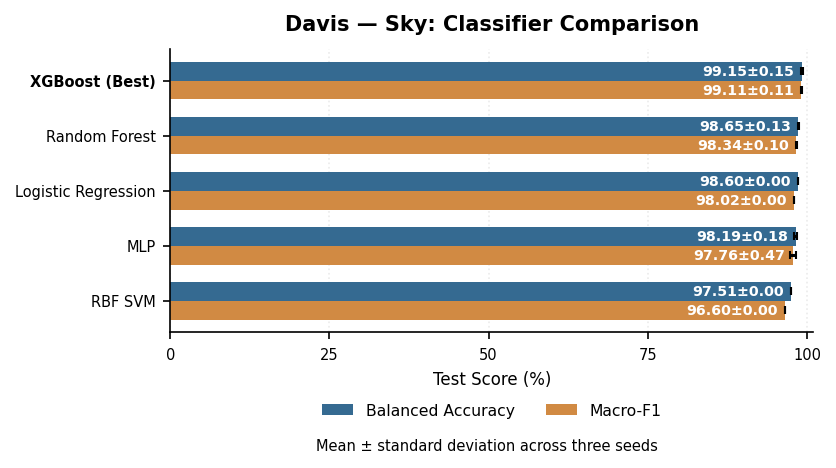

Saved: P1_Davis_Generation_Models.pdf


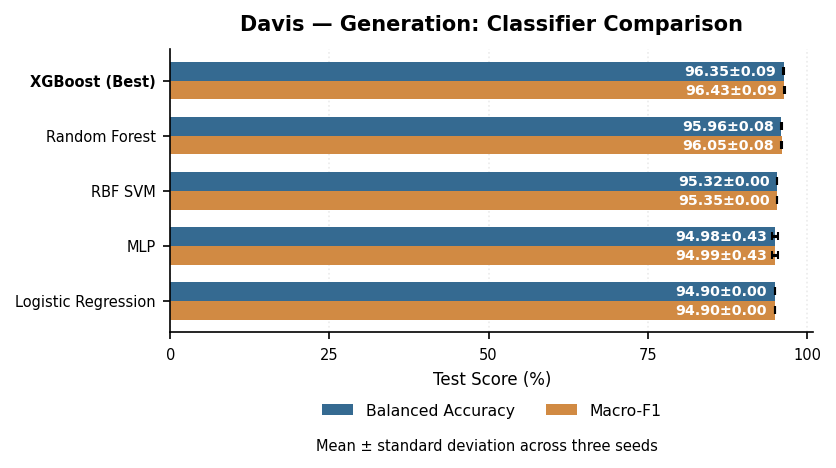

Saved: P1_Amherst_Sky_Models.pdf


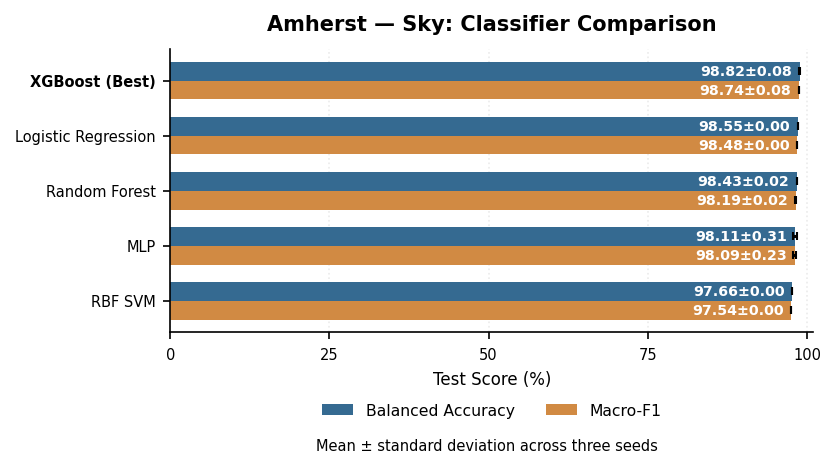

Saved: P1_Amherst_Generation_Models.pdf


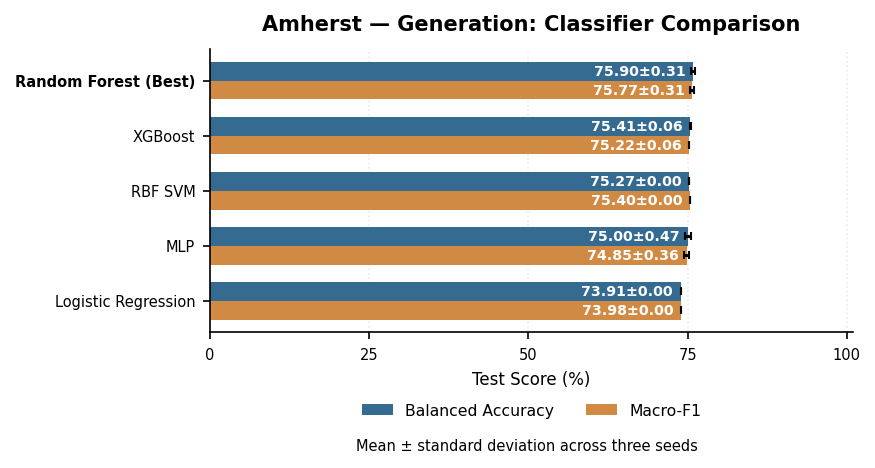

Saved: P1_Davis_Sky_Confusion.pdf


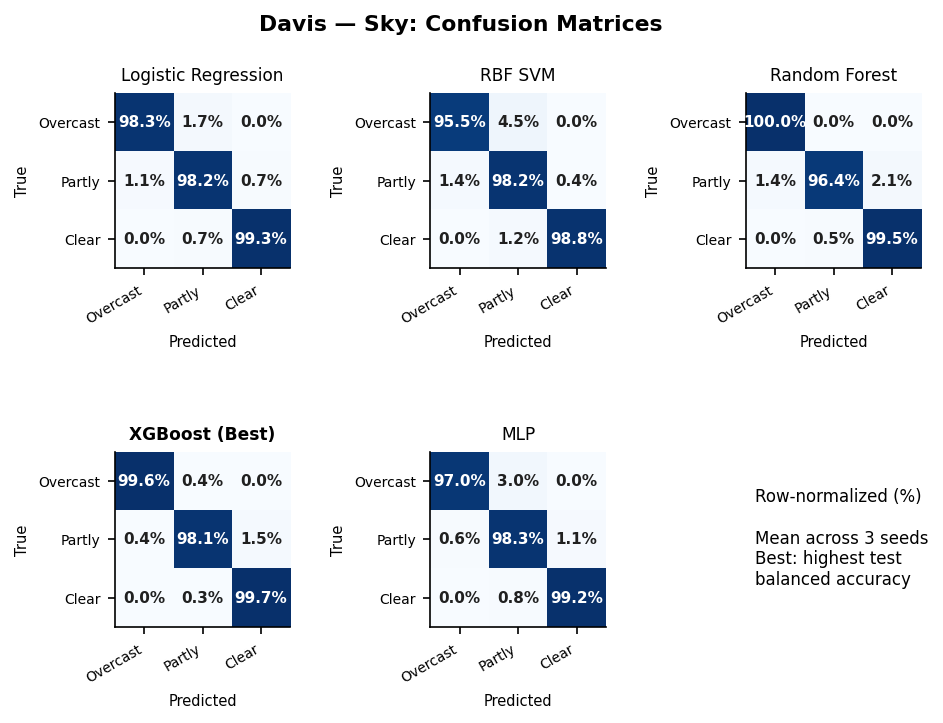

Saved: P1_Davis_Generation_Confusion.pdf


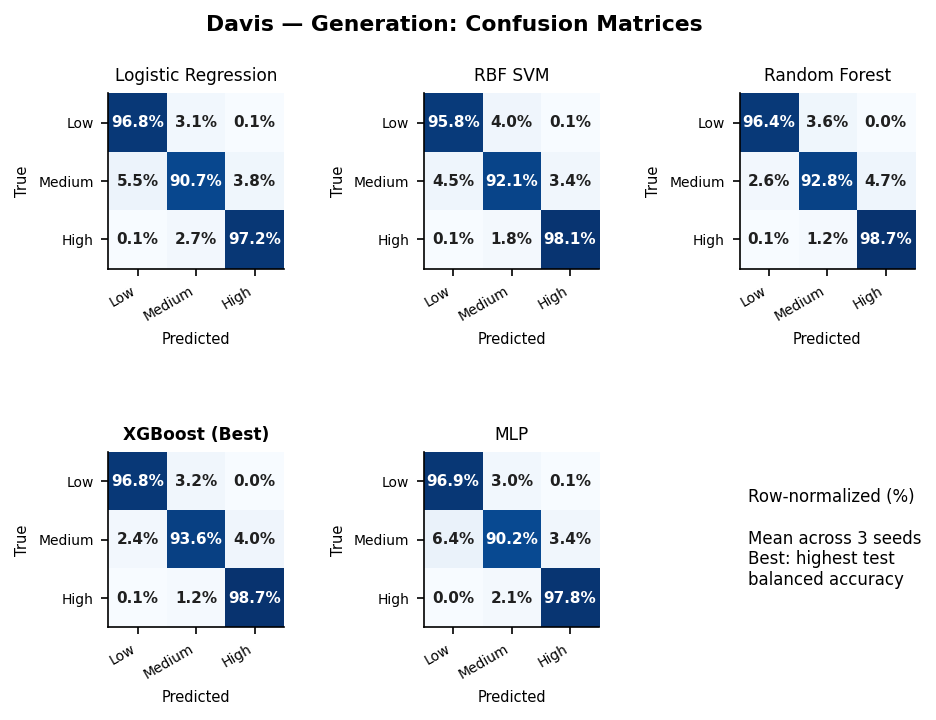

Saved: P1_Amherst_Sky_Confusion.pdf


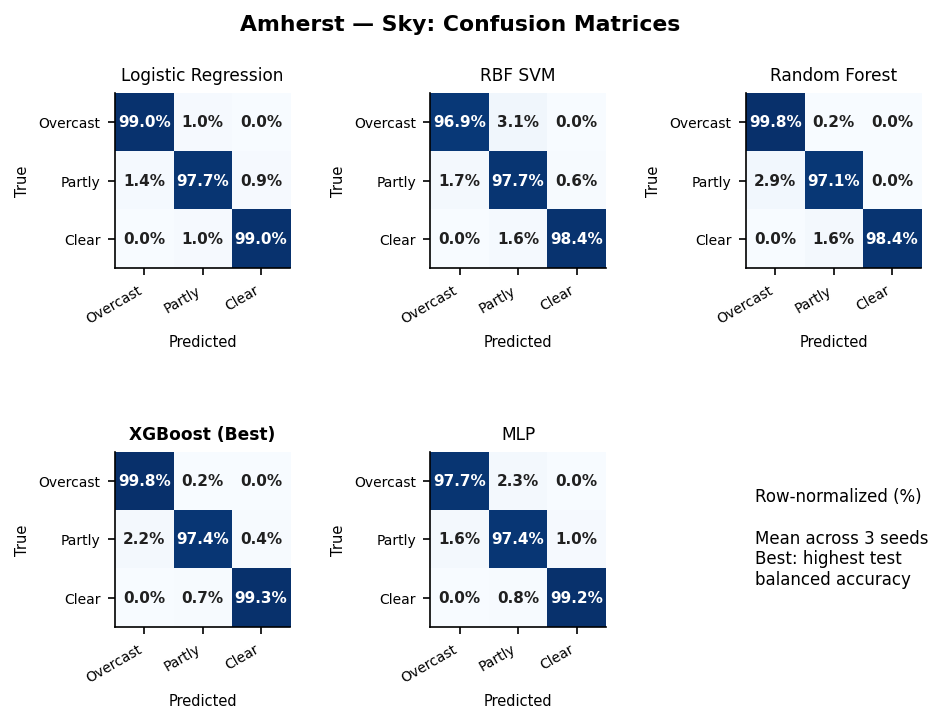

Saved: P1_Amherst_Generation_Confusion.pdf


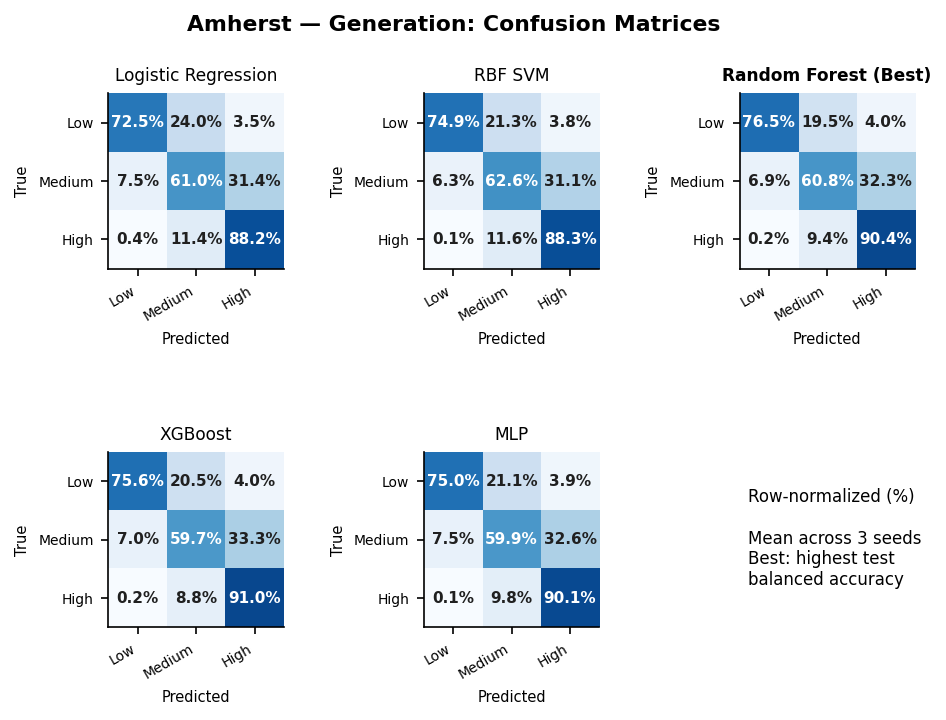

Saved: P1_Per_Class_Best_Models.pdf


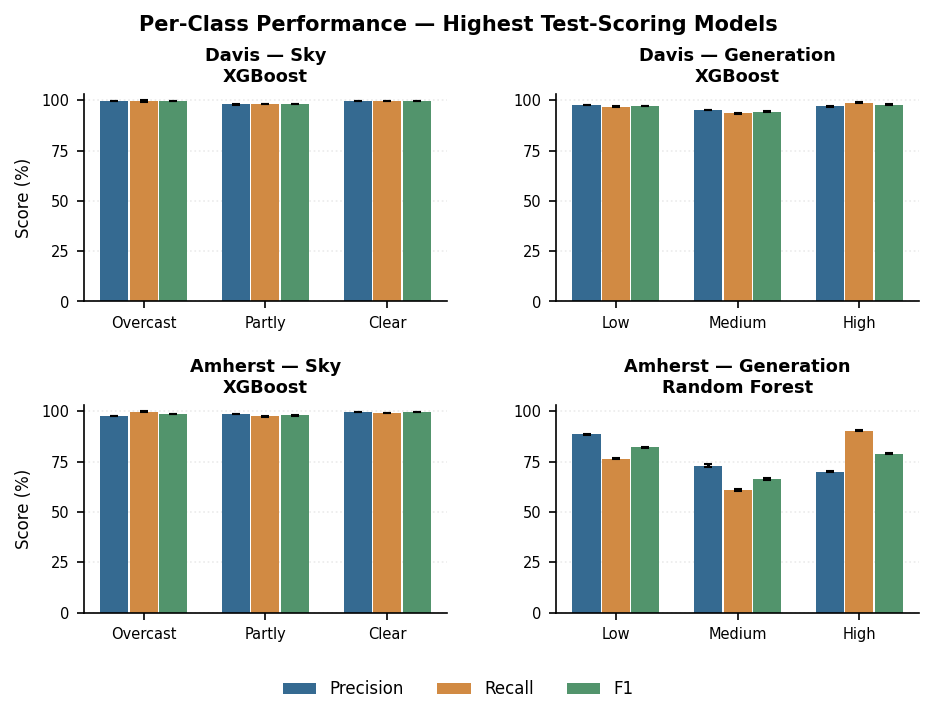

Saved: P1_Output_Power_Ablation.pdf


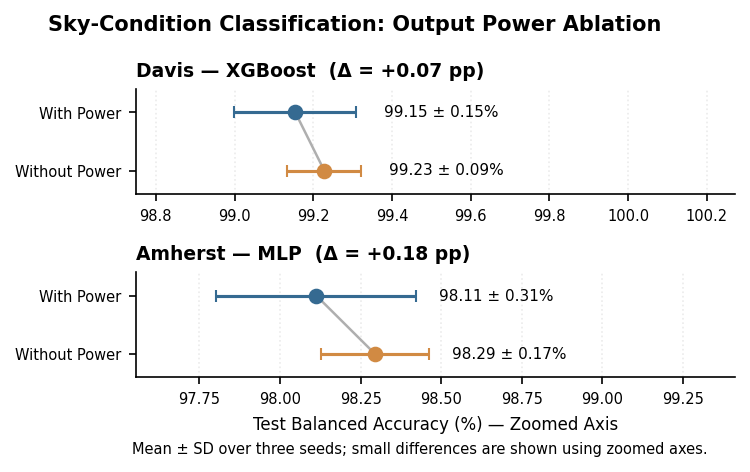


P1 — FINAL VISUALIZATION SUMMARY
Figures generated : 10
  4 model-comparison figures
  4 multi-model confusion-matrix figures
  1 per-class performance figure
  1 feature-ablation figure

PDF files saved in: /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Figures/P1


In [16]:

# ============================================================
# P1 — Cell 9: Overall Results and Visualizations
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# 1. Figure configuration
# ------------------------------------------------------------

SAVE_FINAL_FIGURES = True  # Change to True when finalized.

REPORT_WIDTH = 6.4
SMALL_WIDTH = 5.4

CITIES = ("Davis", "Amherst")
TASKS = ("Sky", "Generation")
PLOT_SEEDS = (42, 123, 2026)

MODELS = (
    "Logistic Regression",
    "SVM (RBF)",
    "Random Forest",
    "XGBoost",
    "MLP (PyTorch)"
)

SHORT_NAMES = {
    "Logistic Regression": "Logistic Regression",
    "SVM (RBF)": "RBF SVM",
    "Random Forest": "Random Forest",
    "XGBoost": "XGBoost",
    "MLP (PyTorch)": "MLP"
}

CLASS_NAMES_SHORT = {
    "Sky": ["Overcast", "Partly", "Clear"],
    "Generation": ["Low", "Medium", "High"]
}

BLUE = "#356A91"
ORANGE = "#D18A43"
GREEN = "#52946C"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 8,
    "axes.titlesize": 9,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "figure.dpi": 150,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "savefig.facecolor": "white"
})

if SAVE_FINAL_FIGURES:
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)

figure_count = 0


def present_figure(fig, filename):
    """Display a figure; optionally save a vector PDF."""

    global figure_count
    figure_count += 1

    if SAVE_FINAL_FIGURES:
        path = FIGURES_DIR / filename
        fig.savefig(
            path,
            format="pdf",
            bbox_inches="tight",
            pad_inches=0.06
        )
        print(f"Saved: {path.name}")

    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# 2. Reload saved metrics and predictions
# ------------------------------------------------------------

metrics = pd.read_csv(
    RESULTS_DIR / "classification_metrics.csv"
)

ablation = pd.read_csv(
    RESULTS_DIR / "sky_power_ablation_metrics.csv"
)

assert len(metrics) == 60
assert len(ablation) == 12

assert not metrics.duplicated(
    ["City", "Task", "Model", "Seed"]
).any()


def load_predictions(city, task, model, seed):
    """Reload predictions from the completed experiments."""

    slug = (
        model.lower()
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
    )

    path = (
        RESULTS_DIR / "Predictions"
        / f"{city}_{task}_{slug}_seed{seed}.npz"
    )

    with np.load(path, allow_pickle=False) as data:
        return (
            data["y_true"].astype(int),
            data["y_pred"].astype(int),
            data["row_index"].astype(int)
        )


# ------------------------------------------------------------
# 3. Aggregate scores and identify observed test leaders
# ------------------------------------------------------------

summary = metrics.groupby(
    ["City", "Task", "Model"],
    as_index=False
).agg(
    Test_BA=("Test Balanced Accuracy", "mean"),
    Test_BA_SD=("Test Balanced Accuracy", "std"),
    Test_F1=("Test Macro-F1", "mean"),
    Test_F1_SD=("Test Macro-F1", "std"),
    Runs=("Seed", "count")
)

assert len(summary) == 20
assert (summary["Runs"] == 3).all()

BEST_MODELS = {}

for city in CITIES:
    for task in TASKS:

        group = summary[
            (summary["City"] == city)
            & (summary["Task"] == task)
        ].sort_values(
            ["Test_BA", "Test_F1", "Model"],
            ascending=[False, False, True]
        )

        BEST_MODELS[(city, task)] = group.iloc[0]["Model"]


print("P1 — OVERALL RESULTS AND VISUALIZATIONS")
print("=" * 65)
print(f"Experiment runs : {len(metrics)}")
print(f"Figure saving   : {SAVE_FINAL_FIGURES}")

print("\nHighest observed test balanced accuracy:")

for city in CITIES:
    for task in TASKS:

        model = BEST_MODELS[(city, task)]

        record = summary[
            (summary["City"] == city)
            & (summary["Task"] == task)
            & (summary["Model"] == model)
        ].iloc[0]

        print(
            f"  {city:8s} | {task:10s} | "
            f"{SHORT_NAMES[model]:19s} | "
            f"{100 * record['Test_BA']:.2f}%"
        )


# ------------------------------------------------------------
# 4. Model comparison: four compact figures
# ------------------------------------------------------------

for city in CITIES:
    for task in TASKS:

        group = summary[
            (summary["City"] == city)
            & (summary["Task"] == task)
        ].sort_values(
            "Test_BA", ascending=False
        ).reset_index(drop=True)

        best_model = BEST_MODELS[(city, task)]

        fig, ax = plt.subplots(
            figsize=(REPORT_WIDTH, 3.2)
        )

        y = np.arange(len(group))
        bar_width = 0.34

        ba = 100 * group["Test_BA"].to_numpy()
        ba_sd = 100 * group["Test_BA_SD"].to_numpy()

        f1 = 100 * group["Test_F1"].to_numpy()
        f1_sd = 100 * group["Test_F1_SD"].to_numpy()

        ax.barh(
            y - bar_width / 2,
            ba,
            height=bar_width,
            xerr=ba_sd,
            color=BLUE,
            capsize=2,
            label="Balanced Accuracy"
        )

        ax.barh(
            y + bar_width / 2,
            f1,
            height=bar_width,
            xerr=f1_sd,
            color=ORANGE,
            capsize=2,
            label="Macro-F1"
        )

        tick_labels = []

        for model in group["Model"]:
            label = SHORT_NAMES[model]
            if model == best_model:
                label += " (Best)"
            tick_labels.append(label)

        ax.set_yticks(y)
        ax.set_yticklabels(tick_labels)
        ax.invert_yaxis()

        for tick, model in zip(
            ax.get_yticklabels(), group["Model"]
        ):
            if model == best_model:
                tick.set_fontweight("bold")

        ax.set_xlim(0, 101)
        ax.set_xticks([0, 25, 50, 75, 100])

        ax.set_xlabel("Test Score (%)")

        ax.set_title(
            f"{city} — {task}: Classifier Comparison",
            fontsize=10,
            fontweight="bold",
            pad=9
        )

        ax.grid(
            axis="x", linestyle=":", alpha=0.25
        )
        ax.set_axisbelow(True)

        # Print mean ± SD directly on the bars.
        for i in range(len(group)):

            for value, sd, offset in (
                (ba[i], ba_sd[i], -bar_width / 2),
                (f1[i], f1_sd[i], bar_width / 2)
            ):

                ax.text(
                    value - 1.2,
                    y[i] + offset,
                    f"{value:.2f}±{sd:.2f}",
                    ha="right",
                    va="center",
                    fontsize=6.8,
                    color="white",
                    fontweight="bold"
                )

        ax.legend(
            loc="upper center",
            bbox_to_anchor=(0.5, -0.20),
            ncol=2,
            fontsize=7.5,
            frameon=False
        )

        fig.text(
            0.64,
            0.035,
            "Mean ± standard deviation across three seeds",
            ha="center",
            fontsize=7
        )

        fig.subplots_adjust(
            left=0.31,
            right=0.98,
            top=0.87,
            bottom=0.28
        )

        present_figure(
            fig,
            f"P1_{city}_{task}_Models.pdf"
        )


# ------------------------------------------------------------
# 5. Confusion matrices: all five models
# ------------------------------------------------------------

for city in CITIES:
    for task in TASKS:

        fig, axes = plt.subplots(
            2, 3,
            figsize=(REPORT_WIDTH, 4.8)
        )

        best_model = BEST_MODELS[(city, task)]

        reference_rows = None
        reference_y = None

        for model_index, model in enumerate(MODELS):

            matrices = []

            for seed in PLOT_SEEDS:

                y_true, y_pred, rows = load_predictions(
                    city, task, model, seed
                )

                # Ensure all comparisons use identical samples.
                if reference_rows is None:
                    reference_rows = rows
                    reference_y = y_true
                else:
                    np.testing.assert_array_equal(
                        reference_rows, rows
                    )
                    np.testing.assert_array_equal(
                        reference_y, y_true
                    )

                cm = confusion_matrix(
                    y_true, y_pred,
                    labels=[0, 1, 2]
                ).astype(float)

                row_totals = cm.sum(
                    axis=1, keepdims=True
                )

                cm_percent = 100 * np.divide(
                    cm,
                    row_totals,
                    out=np.zeros_like(cm),
                    where=row_totals > 0
                )

                matrices.append(cm_percent)

            mean_cm = np.mean(matrices, axis=0)

            ax = axes.flat[model_index]

            ax.imshow(
                mean_cm,
                cmap="Blues",
                vmin=0,
                vmax=100
            )

            is_best = model == best_model

            title = SHORT_NAMES[model]
            if is_best:
                title += " (Best)"

            ax.set_title(
                title,
                fontsize=8.2,
                fontweight=(
                    "bold" if is_best else "normal"
                ),
                pad=6
            )

            labels = CLASS_NAMES_SHORT[task]

            ax.set_xticks(
                [0, 1, 2],
                labels,
                rotation=30,
                ha="right"
            )

            ax.set_yticks(
                [0, 1, 2],
                labels
            )

            ax.tick_params(labelsize=6.7)

            ax.set_xlabel("Predicted", fontsize=7)
            ax.set_ylabel("True", fontsize=7)

            for i in range(3):
                for j in range(3):

                    value = mean_cm[i, j]

                    ax.text(
                        j, i,
                        f"{value:.1f}%",
                        ha="center",
                        va="center",
                        fontsize=7.3,
                        fontweight="bold",
                        color=(
                            "white"
                            if value >= 55
                            else "#202020"
                        )
                    )

        # Explain normalization in the unused sixth panel.
        axes.flat[5].axis("off")

        axes.flat[5].text(
            0.05, 0.70,
            "Row-normalized (%)",
            fontsize=8,
            transform=axes.flat[5].transAxes
        )

        axes.flat[5].text(
            0.05, 0.48,
            "Mean across 3 seeds",
            fontsize=8,
            transform=axes.flat[5].transAxes
        )

        axes.flat[5].text(
            0.05, 0.26,
            "Best: highest test\nbalanced accuracy",
            fontsize=8,
            transform=axes.flat[5].transAxes
        )

        fig.suptitle(
            f"{city} — {task}: Confusion Matrices",
            fontsize=10.5,
            fontweight="bold",
            y=0.98
        )

        fig.subplots_adjust(
            left=0.14,
            right=0.98,
            top=0.88,
            bottom=0.12,
            wspace=0.80,
            hspace=0.90
        )

        present_figure(
            fig,
            f"P1_{city}_{task}_Confusion.pdf"
        )


# ------------------------------------------------------------
# 6. Per-class performance of best test-performing models
# ------------------------------------------------------------

per_class_records = []

for city in CITIES:
    for task in TASKS:

        model = BEST_MODELS[(city, task)]

        for seed in PLOT_SEEDS:

            y_true, y_pred, _ = load_predictions(
                city, task, model, seed
            )

            report = classification_report(
                y_true,
                y_pred,
                labels=[0, 1, 2],
                target_names=CLASS_NAMES_SHORT[task],
                output_dict=True,
                zero_division=0
            )

            for class_name in CLASS_NAMES_SHORT[task]:

                per_class_records.append({
                    "City": city,
                    "Task": task,
                    "Class": class_name,
                    "Precision": report[class_name]["precision"],
                    "Recall": report[class_name]["recall"],
                    "F1": report[class_name]["f1-score"]
                })


per_class = pd.DataFrame(per_class_records)

per_class_summary = per_class.groupby(
    ["City", "Task", "Class"],
    as_index=False
)[["Precision", "Recall", "F1"]].agg(
    ["mean", "std"]
)

# Flatten the multi-level columns.
per_class_summary.columns = [
    "_".join(filter(None, col))
    for col in per_class_summary.columns.to_flat_index()
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(REPORT_WIDTH, 4.8)
)

metric_config = [
    ("Precision", BLUE),
    ("Recall", ORANGE),
    ("F1", GREEN)
]

for i, city in enumerate(CITIES):
    for j, task in enumerate(TASKS):

        ax = axes[i, j]

        group = per_class_summary[
            (per_class_summary["City"] == city)
            & (per_class_summary["Task"] == task)
        ].set_index("Class").loc[
            CLASS_NAMES_SHORT[task]
        ]

        x = np.arange(3)

        for k, (metric_name, color) in enumerate(
            metric_config
        ):

            means = (
                group[f"{metric_name}_mean"].to_numpy()
                * 100
            )

            stds = (
                group[f"{metric_name}_std"].to_numpy()
                * 100
            )

            ax.bar(
                x + (k - 1) * 0.24,
                means,
                width=0.23,
                yerr=stds,
                capsize=2,
                color=color,
                label=metric_name
            )

        ax.set_xticks(x)
        ax.set_xticklabels(
            CLASS_NAMES_SHORT[task]
        )

        ax.set_ylim(0, 103)
        ax.set_yticks([0, 25, 50, 75, 100])

        ax.set_title(
            f"{city} — {task}\n"
            f"{SHORT_NAMES[BEST_MODELS[(city, task)]]}",
            fontsize=8.5,
            fontweight="bold"
        )

        if j == 0:
            ax.set_ylabel("Score (%)")

        ax.grid(
            axis="y", linestyle=":", alpha=0.25
        )
        ax.set_axisbelow(True)

handles, legend_labels = (
    axes[0, 0].get_legend_handles_labels()
)

fig.legend(
    handles,
    legend_labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=3,
    fontsize=8,
    frameon=False
)

fig.suptitle(
    "Per-Class Performance — Highest Test-Scoring Models",
    fontsize=10,
    fontweight="bold",
    y=0.98
)

fig.subplots_adjust(
    left=0.11,
    right=0.98,
    top=0.87,
    bottom=0.15,
    wspace=0.30,
    hspace=0.50
)

present_figure(
    fig,
    "P1_Per_Class_Best_Models.pdf"
)


# ------------------------------------------------------------
# 7. Output Power ablation: compact and readable
# ------------------------------------------------------------

ablation_summary = ablation.groupby(
    ["City", "Model", "Power Feature"],
    as_index=False
).agg(
    Mean=("Test Balanced Accuracy", "mean"),
    SD=("Test Balanced Accuracy", "std")
)

fig, axes = plt.subplots(
    2, 1,
    figsize=(SMALL_WIDTH, 3.1)
)

condition_config = (
    ("Included", "With Power", BLUE),
    ("Excluded", "Without Power", ORANGE)
)

for i, city in enumerate(CITIES):

    ax = axes[i]

    group = ablation_summary[
        ablation_summary["City"] == city
    ].set_index("Power Feature")

    model = group["Model"].iloc[0]

    means = group["Mean"] * 100
    stds = group["SD"] * 100

    for j, (condition, label, color) in enumerate(
        condition_config
    ):

        mean = float(means.loc[condition])
        std = float(stds.loc[condition])

        y = 1 - j

        ax.errorbar(
            mean,
            y,
            xerr=std,
            fmt="o",
            markersize=6.5,
            capsize=3,
            color=color,
            zorder=3
        )

        # Labels stay beyond the error bars.
        ax.text(
            mean + std + 0.07,
            y,
            f"{mean:.2f} ± {std:.2f}%",
            fontsize=7.3,
            va="center"
        )

    included = float(means.loc["Included"])
    excluded = float(means.loc["Excluded"])

    difference = excluded - included

    ax.plot(
        [included, excluded],
        [1, 0],
        color="#AFAFAF",
        linewidth=1.2,
        zorder=1
    )

    ax.set_yticks(
        [1, 0],
        ["With Power", "Without Power"]
    )

    ax.set_ylim(-0.40, 1.40)

    min_x = min(
        included - float(stds.loc["Included"]),
        excluded - float(stds.loc["Excluded"])
    )

    max_x = max(
        included + float(stds.loc["Included"]),
        excluded + float(stds.loc["Excluded"])
    )

    # The axis is zoomed to show small differences.
    ax.set_xlim(min_x - 0.25, max_x + 0.95)

    ax.set_title(
        f"{city} — {SHORT_NAMES[model]}  "
        f"(Δ = {difference:+.2f} pp)",
        fontsize=9,
        fontweight="bold",
        loc="left"
    )

    ax.grid(
        axis="x", linestyle=":", alpha=0.25
    )
    ax.set_axisbelow(True)

axes[-1].set_xlabel(
    "Test Balanced Accuracy (%) — Zoomed Axis"
)

fig.suptitle(
    "Sky-Condition Classification: Output Power Ablation",
    fontsize=10,
    fontweight="bold",
    y=0.98
)

fig.text(
    0.58, 0.035,
    "Mean ± SD over three seeds; "
    "small differences are shown using zoomed axes.",
    ha="center",
    fontsize=7
)

fig.subplots_adjust(
    left=0.23,
    right=0.97,
    top=0.82,
    bottom=0.20,
    hspace=0.75
)

present_figure(
    fig,
    "P1_Output_Power_Ablation.pdf"
)


# ------------------------------------------------------------
# 8. Completion summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("P1 — FINAL VISUALIZATION SUMMARY")
print("=" * 65)

print(f"Figures generated : {figure_count}")
print("  4 model-comparison figures")
print("  4 multi-model confusion-matrix figures")
print("  1 per-class performance figure")
print("  1 feature-ablation figure")

if SAVE_FINAL_FIGURES:
    print(f"\nPDF files saved in: {FIGURES_DIR}")
else:
    print("\nPREVIEW MODE — No figures were saved.")
    print(
        "Set SAVE_FINAL_FIGURES = True "
        "when all figures are finalized."
    )
